# Two-photon: choice selectivity

Figures 5B, 5C, 5D, 5E, 5F, S12A, S12C, S12D (bottom) and S12E–S12J.

**Reads** (`data/2p/`, run `2p_0_preprocessing` first if they are missing):
`data_runs_Unnormalized.pkl`, `sgf_all.pkl`, `qall_res_dict.pkl`,
`df_all_by_epoch_df_f_filtered.pkl`, `df_all_by_trial_normalized.pkl`,
`unnormalized_3_quantiles_0.1s_before_sampling_0.1s_after_movement.pkl`, the upstream
`normalized_0.1s_before_sampling_0.1s_after_movement.pkl`, and the decoder
results `svm_df.pkl`.

**Writes**: figures under `results/2P/` with `SAVE_FIGS`; `svm_df.pkl` only
when the decoder is re-run (`LOAD_SVM_FROM_PICKLE = False`) with `SAVE_DATA`.

# Run this to enable loading from relative paths

In [ ]:
%load_ext autoreload
%autoreload 2
if "PKG" not in globals():
  import importlib, sys, pathlib # https://stackoverflow.com/a/50395128/11996983
  PKG = %pwd
  PKG = pathlib.Path(PKG)
  root_parent_level = 1
  root = PKG
  full_pkg = f"{root.name}"
  for _ in range(root_parent_level):
    root = root.parent
    full_pkg = f"{root.name}.{full_pkg}"
    MODULE_PATH = str(root / "__init__.py")
    MODULE_NAME = f"{root.name}"
    spec = importlib.util.spec_from_file_location(MODULE_NAME, MODULE_PATH)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
  __package__ = full_pkg


# Save plots with no embeded fonts

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

# Parameters

In [ ]:
# Papermill parameters -- code/run_notebooks.py overrides these.
# Everything is off by default, so running the notebook writes nothing.
SAVE_FIGS = False           # write figures under results/
SAVE_DATA = False           # rewrite cached intermediate data under data/
PAPER_FIGURES_ONLY = False  # skip per-subject / per-session figures

In [ ]:
import pathlib

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from .common.definitions import BrainRegion

PVAL = 0.05
BINS_COUNT = 7

fig_save_prefix = "../results/2P/"
pathlib.Path(fig_save_prefix).mkdir(exist_ok=True)

# Load source data

In [ ]:
from .twop.dataload import loadMaxFiringFrame, loadRunData, loadSamplingNormalized
from .twop.samplingquantiles import assignQuantileIdx

# Every trial's sampling epoch, stretched to a common length, labelled fast (1) /
# typical (2) / slow (3) by sampling time.
normed_sampling_df = assignQuantileIdx(
    loadSamplingNormalized(time_before=0.1, time_after=0.1))
# Each neuron's peak sample per trial, on all / fast / typical / slow trials
# (written by 2p_0_preprocessing).
max_firing_all_df = loadMaxFiringFrame("all")
max_firing_q1_df = loadMaxFiringFrame("fast")
max_firing_q2_df = loadMaxFiringFrame("typical")
max_firing_q3_df = loadMaxFiringFrame("slow")
# The per-neuron ROC tests (written by 2p_0_preprocessing); run 0 is the real data.
run_data_unnormalized = loadRunData("Unnormalized")

In [ ]:
import pandas as pd
# Shared with other notebooks and unit-tested:
# maxFiringHist -> twop/movementneurons.py, extractIQR -> twop/seqdeviation.py
from .twop.movementneurons import maxFiringHist
from .twop.seqdeviation import extractIQR

In [ ]:
# PVAL stays this notebook's single p-value knob; the selection itself is
# twop/movementneurons.py's, unit-tested there.
from functools import partial

from .twop.movementneurons import getSgfNeurons as _getSgfNeurons

getSgfNeurons = partial(_getSgfNeurons, pval=PVAL)

# Sgf. Neurons Pie Charts — Figure 5C

For: ChoiceLeft None
	LFC: 33.00% ±3.68%
	MFC: 18.06% ±3.04%
Sgf. neurons for Cur. Direction (ChoiceLeft) - % of all neurons
    MFC: 18.06% +/- 3.04% SEM  (13 sessions, 182/837 neurons)
    LFC: 33.00% +/- 3.68% SEM  (10 sessions, 199/609 neurons)
    Normality (Shapiro-Wilk): MFC p=0.905, LFC p=0.253 -> normal, t-test usable
    MFC vs LFC: t-test (Student) stat=-3.15, p=0.00478 (MannWhitneyU p=0.0143 for reference)


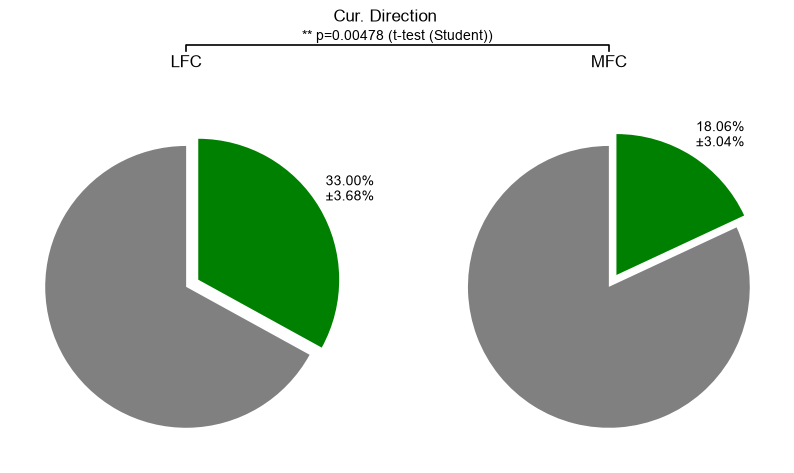

For: IsEasy ChoiceLeft
	LFC: 10.39% ±2.30%
	MFC: 7.44% ±1.35%
For: IsEasy None
	LFC: 7.60% ±1.75%
	MFC: 5.82% ±1.00%
For: PrevChoiceCorrect None
	LFC: 49.68% ±4.12%
	MFC: 55.08% ±3.66%


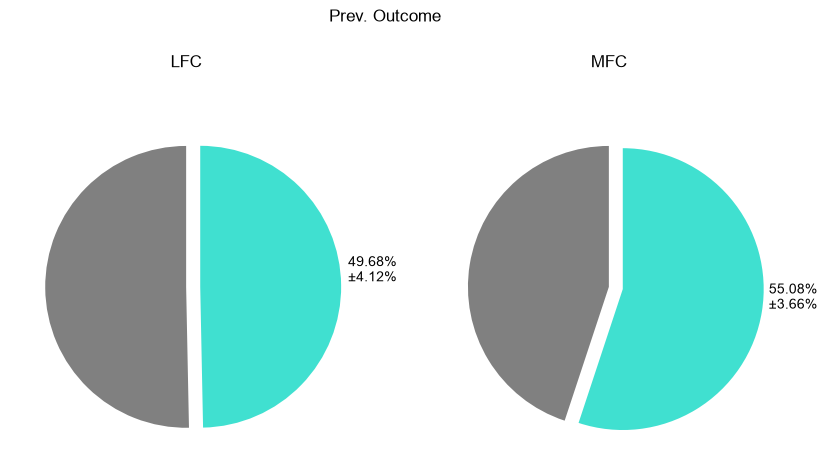

For: PrevChoiceLeft None
	LFC: 74.00% ±3.34%
	MFC: 73.27% ±2.63%


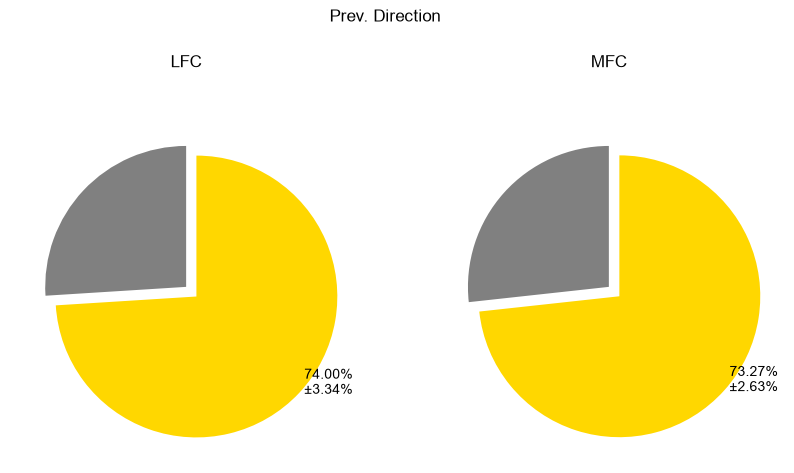

For: PrevIsEasy None
	LFC: 16.57% ±3.43%
	MFC: 12.27% ±2.51%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from typing import Union

from .twop import sgfneurons as sgn

def loopPlotPieChart(df, save_prefix=None, save_figs=False,
                     title_prefix="", show_selectivity=False,
                     filter_df=None):
    if show_selectivity:
        title_prefix = f"{title_prefix}split_"
    if filter_df is not None:
        title_prefix = f"{title_prefix}filtered_"
    df = df[df.DVstr.isnull()]
    assert "quantile_idx" not in df.columns

    for (data_col, prior_data_col), grp_df in df.groupby(["data_col",
                                                          "prior_data_col"],
                                                          dropna=False):
        if not isinstance(prior_data_col, str):
            assert np.isnan(prior_data_col)
            prior_data_col = None
        if prior_data_col is not None or data_col in ["IsEasy", "PrevIsEasy"]:
            plot = False
        else:
            plot = True
            fig, axs = plt.subplots(1, 2, figsize=(10, 5))
            axs = iter(axs)
            color = "g" if data_col == "ChoiceLeft" else (
                    "gold" if data_col == "PrevChoiceLeft" else
                    "turquoise" if data_col == "PrevChoiceCorrect" else
                    "purple" if data_col == "ChoiceCorrect" else
                    "orange")
        print("For:", data_col, prior_data_col)
        data_col_str = "Cur. Direction" if data_col == "ChoiceLeft" else \
                       "Prev. Direction" if data_col == "PrevChoiceLeft" else \
                       "Prev. Outcome" if data_col == "PrevChoiceCorrect" else \
                       "Cur. Outcome" if data_col == "ChoiceCorrect" else \
                       data_col

        def calcSessSGFMean(sess_df, check_ROC_left : Union[None, True, False]=None):
            if filter_df is not None:
                assert sess_df.ShortName.nunique() == 1, \
                    f"Expected only one session in sess_df, got {sess_df.ShortName.nunique()}"
                short_name = sess_df.ShortName.iloc[0]
                filter_sess_df = filter_df[filter_df.ShortName == short_name]
                len_before = len(sess_df)
                sess_df = sess_df[sess_df.trace_id.isin(filter_sess_df.trace_id)]
                assert len(sess_df) > 0, \
                    f"After filtering, sess_df is empty for {short_name} with {filter_df.columns = }"
                len_after = len(sess_df)
            nerons_count = len(sess_df)
            sgf_idx = sess_df.pval <= PVAL
            if check_ROC_left is not None:
                sgf_idx &= sess_df.IsROCLeftTuend == check_ROC_left
            sgf_count = sgf_idx.sum()
            return 100 * sgf_count / nerons_count

        def getGroupMeanSEM(sub_df, check_ROC_left : Union[None, True, False]=None):
            mean_sess_sgf = sub_df.groupby("ShortName").apply(calcSessSGFMean,
                                                             check_ROC_left=check_ROC_left)
            sgf_mean, sgf_sem = mean_sess_sgf.mean(), mean_sess_sgf.sem()
            print(f"\t{br_str}: {sgf_mean:.2f}% ±{sgf_sem:.2f}%")
            return sgf_mean, sgf_sem

        for br, br_df in grp_df.groupby("BrainRegion"):
            br_str = str(BrainRegion(br)).split("_")[0]
            br_str = "MFC" if br_str == "M2" else "LFC"
            if show_selectivity:
                sgf_mean_left, sgf_sem_left = getGroupMeanSEM(br_df, check_ROC_left=True)
                sgf_mean_right, sgf_sem_right = getGroupMeanSEM(br_df, check_ROC_left=False)
                pie_x = [100-sgf_mean_left-sgf_mean_right, sgf_mean_left, sgf_mean_right]
                pie_labels = ["", f"{sgf_mean_left:.2f}%\n±{sgf_sem_left:.2f}%",
                              f"{sgf_mean_right:.2f}%\n±{sgf_sem_right:.2f}%"]
                explode = [0, 0.1, 0.1]
                clrs = ["gray", color, color]
                hatches = [None, None, "x"]
            else:
                sgf_mean, sgf_sem = getGroupMeanSEM(br_df)
                pie_x = [100-sgf_mean, sgf_mean]
                pie_labels = ["", f"{sgf_mean:.2f}%\n±{sgf_sem:.2f}%"]
                explode = [0, 0.1]
                clrs = ["gray", color]
                hatches = None
            if plot:
                ax = next(axs)
                wedges, texts = ax.pie(pie_x,
                                       labels=pie_labels,
                                       startangle=90,
                                       explode=explode,
                                       labeldistance=1.05,
                                       textprops={"va": "bottom", "ha": "left"},
                                       colors=clrs,
                                       hatch=hatches)
                if not show_selectivity:
                    ax.set_title(f"{br_str}", y=1.1)
                if show_selectivity:
                    ax.set_title(f"{br_str} - (x hatch: anti-selective for {data_col})",
                                 y=1.1)
                    # Put the exploded wedges together as one piece, not two
                    # separate exploded pieces
                    # https://stackoverflow.com/a/70578760/11996983
                    groups = [[0], [1, 2]]
                    radfraction = 0.1
                    for group in groups:
                        if len(group) == 1:
                            wedges[0].set_visible(False)
                            print(ax.get_xlim(), ax.get_ylim())
                            ax.set_xlim(0, 1.25)
                            ax.set_ylim(0, 1.25)
                            continue
                        ang = np.deg2rad((wedges[group[-1]].theta2 + wedges[group[0]].theta1) / 2)
                        for j in group:
                            center = radfraction * wedges[j].r * np.array([np.cos(ang), np.sin(ang)])
                            wedges[j].set_center(center)
                            texts[j].set_position(np.array(texts[j].get_position()) + center)

        if plot:
            prior_data_col_str = "" if prior_data_col is None else f" - {prior_data_col}"
            title = title_prefix.replace("_"," ")  + f"{data_col_str}{prior_data_col_str}"
            if filter_df is not None:
                title += " - Filtered on active neurons"
            fig.suptitle(title, y=1.05)
            # Significance bracket between the two pies' MFC / LFC titles, with
            # the stars, the p-value and the test that produced it. Only for the
            # Cur. Direction figure -- that single planned MFC-vs-LFC comparison
            # is the one sgn.regionComparison runs (see twop/sgfneurons.py) --
            # and only for the plain, unfiltered pies, whose percentages are
            # exactly the ones it tests. Drawn after the suptitle, which it
            # nudges up if the label would reach it.
            if (not show_selectivity and filter_df is None
                    and data_col == sgn.CHOICE_DATA_COL):
                sgf_comparison = sgn.regionComparison(df, pval=PVAL,
                                                      data_col=data_col)
                print(sgn.formatComparison(sgf_comparison))
                sgn.drawRegionSigBracket(fig, fig.axes, sgf_comparison)
            if save_figs:
                fig.savefig(f"{save_prefix}/sgf_tests/{title_prefix}{title}.svg",
                            bbox_inches='tight')
            plt.show()

loopPlotPieChart(run_data_unnormalized[0].shortlong_df, show_selectivity=False,
                 save_prefix=fig_save_prefix, save_figs=SAVE_FIGS)


## Choice-selective neurons at sampling start, fast vs slow — Figure S12C

In [ ]:
from .twop import samplingstartchoice as ssc
from .twop.dataload import loadSamplingUnnormalized

# Figure S12C: the paper's choice test (peak activity, Mann-Whitney) re-run on
# fast, medium and slow trials over only the first 0.1 s of sampling (takes a
# few minutes). Bars: mean +/- SEM across sessions of the % choice-selective.
ssc.plotChoiceShare(
    ssc.choiceShareBySession(
        ssc.samplingStartChoiceTests(loadSamplingUnnormalized()), pval=PVAL),
    save_figs=SAVE_FIGS, fig_save_prefix=fig_save_prefix)

In [ ]:
from .twop import sgfneurons as sgn

# MFC vs LFC on the very percentages the pie charts above show (per-session
# % of sgf. neurons, mean +/- SEM over sessions -- sgn.perSessionSgfPrcnt
# mirrors loopPlotPieChart's calcSessSGFMean). The pie charts plot those means
# but run no test between the regions; this adds it.
# Normality is checked FIRST (Shapiro-Wilk per region, since the regions are
# independent samples of different sessions): both normal -> two-sample t-test,
# with Levene picking Student vs Welch, otherwise Mann-Whitney U. Both p-values
# stay in the table (ttest_pval / mwu_pval) next to the one the gate selected.
sgf_region_df = sgn.regionComparison(run_data_unnormalized[0].shortlong_df,
                                     pval=PVAL)
print(sgn.formatComparison(sgf_region_df))
display(sgf_region_df.round(4))

Sgf. neurons for Cur. Direction (ChoiceLeft) - % of all neurons
    MFC: 18.06% +/- 3.04% SEM  (13 sessions, 182/837 neurons)
    LFC: 33.00% +/- 3.68% SEM  (10 sessions, 199/609 neurons)
    Normality (Shapiro-Wilk): MFC p=0.905, LFC p=0.253 -> normal, t-test usable
    MFC vs LFC: t-test (Student) stat=-3.15, p=0.00478 (MannWhitneyU p=0.0143 for reference)


,data_col,label,MFC_n_sessions,MFC_mean,MFC_sem,MFC_n,MFC_total,LFC_n_sessions,LFC_mean,LFC_sem,...,MFC_shapiro_pval,LFC_shapiro_W,LFC_shapiro_pval,is_normal,levene_pval,test,statistic,pval,ttest_pval,mwu_pval
0,ChoiceLeft,Cur. Direction,13,18.0628,3.0415,182,837,10,33.0029,3.6807,...,0.9055,0.9058,0.2534,True,0.8571,t-test (Student),-3.1545,0.0048,0.0048,0.0143


# Choice sequence heatmap and example neurons — Figure 5B

As in `2p_2_sequences`, every heatmap combination is first run with
`save_figs=False` to fill the plotting cache, then the figures are drawn.

In [ ]:
from .pipeline import tracesnormalize
from .twop import sessionheatmaps as sh
from .twop.alignsampling import alignSampling
from .twop.dataload import loadFilteredDfF
from .twop.samplingquantiles import assignQuantileIdxByTrial
from .twop.sessionheatmaps import HeatmapFirinhRangeOptions, HeatmapSortingOptions

TIME_BEFORE_SAMPLING = 0.1
TIME_AFTER_MOVEMENT = 0.1
NUM_QUANTILES = 3

# Every trial's sampling epoch from the dF/F traces, stretched to a common
# length and z-scored per neuron.
heatmap_context = sh.makeContext(
    cache_extra_prefix=(f"normalized_sampling_{NUM_QUANTILES}_quantiles_align_"
                        f"{TIME_BEFORE_SAMPLING}s_before_sampling_"
                        f"{TIME_AFTER_MOVEMENT}s_after_movement"),
    fig_save_prefix=fig_save_prefix)

In [ ]:
%%capture
heatmap_sampling_df = alignSampling(loadFilteredDfF(), normalize_epoch_time=True,
                                    time_before_sampling=TIME_BEFORE_SAMPLING,
                                    time_after_sampling=TIME_AFTER_MOVEMENT,
                                    normalization=tracesnormalize.NormalizeZScore(set_name="neuronal"),
                                    normalize_sessions_before_splitting=True)
heatmap_sampling_df["epoch"] = "Sampling"

In [ ]:
%%capture
success = False
# Create first a common All-quantiles heatmap (without breaking to quantiles)
# To use it as sorting reference.
# This run only builds the cache; its figures are discarded (%%capture,
# save_figs=False).
sh.loopHeatmapCombinations(heatmap_sampling_df, heatmap_context, split_by_quantile=False, save_figs=False)
# Reached only if the call above did not raise
success = True

In [ ]:
assert success, "Failed to create the cache properly"

In [ ]:
# Assign quantiles
normed_sampling_quantiles_df = assignQuantileIdxByTrial(heatmap_sampling_df)

  0%|          | 0/23 [00:00<?, ?it/s]

In [ ]:
%%capture
success_quantiles = False
# Also cache the averaged quantile traces
sh.loopHeatmapCombinations(normed_sampling_quantiles_df, heatmap_context, split_by_quantile=True, save_figs=False)
# Reached only if the call above did not raise
success_quantiles = True

In [ ]:
assert success_quantiles, "Failed to create the quantile cache properly"

## Figure 5B (left)

In [ ]:
# Figure 5B: the paper's example, saved in every run that saves.
sh.loopHeatmapCombinations(normed_sampling_quantiles_df, heatmap_context, split_by_quantile=False, save_figs=SAVE_FIGS,
                        plot_only_sess_li=["GP4_28_S2_L51_D250_M2L"],
                        heatmap_sorting_options_li=[HeatmapSortingOptions.SORT_TO_SELF],
                        heatmap_firing_range_options_li=[HeatmapFirinhRangeOptions.SELF_RNG],
                        )

*****Processing: _combination.name = 'All' - _combin_all_sess = False - _resort_to_another = False - _another_is_all = False - not_shared_rng = True - _sgf_data_col = None - _sgf_prior_data_col = None split_by_quantile = False
Processing All
Found in cache: normalized_sampling_3_quantiles_align_0.1s_before_sampling_0.1s_after_movement../results/2P/_All_split5
Splitting....
gen_by_processors: ['epoch']
Processing: Split data by trial ['Name', 'Date', 'SessionNum', 'BrainRegion', 'Layer']
Processing: Split data by trial ['epoch']
Processing: Normalized trace between its 0% and 100% percentile values
Processing: Ordering activity by peak activity ascendingly
Processing: Plotting traces data as heatmap


### All sessions

In [ ]:
# Every session, not only the paper's example: skipped by a paper-only run.
sh.loopHeatmapCombinations(normed_sampling_quantiles_df, heatmap_context, split_by_quantile=False, save_figs=SAVE_FIGS and not PAPER_FIGURES_ONLY,
                        heatmap_sorting_options_li=[HeatmapSortingOptions.SORT_TO_SELF],
                        heatmap_firing_range_options_li=[HeatmapFirinhRangeOptions.SELF_RNG],
                        )

## Figure S12A — rightward vs leftward choices, GP4_28_S2_L51_D250_M2L

In [ ]:
from .twop.dataload import loadTrialNormalized

# The sampling epoch of every neuron of the 5B session, on rightward and
# leftward choices; rows ordered by the session's all-trials heatmap.
sh.epochDirectionHeatmaps(loadTrialNormalized(), "Sampling",
                          sessions=["GP4_28_S2_L51_D250_M2L"],
                          save_figs=SAVE_FIGS, fig_save_prefix=fig_save_prefix)

In [ ]:
%%capture
success_traces_choices = False
# Build cache for choices averaged
sh.loopCombinationsTraces(normed_sampling_quantiles_df, heatmap_context, only_sgf=True,
                       split_by_quantile=False, save_figs=False)
# Reached only if the call above did not raise
success_traces_choices = True

In [ ]:
assert success_traces_choices, "Failed to create the traces choices cache properly"

## Figure 5B (right) — neurons labelled #9, #38 and #46 = trace ids 2, 95 and 20 of GP4_28_S2_L51_D250_M2L

In [ ]:
# Figure 5B (right): the paper's three example neurons, saved in every run that
# saves. The paper labels them "#9", "#38" and "#46"; they are trace ids 2, 95
# and 20. #46 is right-tuned: its higher curve is DecisionRight. They are not
# in the smoothed (only_sgf) subset, so they
# come from the every-neuron pass, which writes under Sessions/**/sgf_and_not_sgf/.
sh.loopCombinationsTraces(normed_sampling_quantiles_df, heatmap_context, only_sgf=False,
                       split_by_quantile=False, save_figs=SAVE_FIGS,
                       plot_only_ids_li=[f"{trace_id}_GP4_28_S2_L51_D250_M2L"
                                         for trace_id in (2, 95, 20)],
                       plot_only_ids_exact_match=True)

## Figure 5D — neuron #9 (trace id 2 of GP4_28_S2_L51_D250_M2L), slow and fast trials

In [ ]:
# Figure 5D: 5B (right)'s neuron #9 (trace id 2) with its trials split by
# strategy. The paper shows slow (quantile_idx=3, top) and fast (quantile_idx=1,
# bottom); the split also writes the typical trials (quantile_idx=2). Written
# under Sessions/**/sgf_and_not_sgf/quantiles/.
sh.loopCombinationsTraces(normed_sampling_quantiles_df, heatmap_context, only_sgf=False,
                       split_by_quantile=True, save_figs=SAVE_FIGS,
                       plot_only_ids_li=["2_GP4_28_S2_L51_D250_M2L"],
                       plot_only_ids_exact_match=True)

### Every session (full run only)

In [ ]:
# Every neuron of every session, Figure 5B (right)'s three included. Both
# only_sgf modes run; they write to different directories:
#   only_sgf=True  -> Sessions/**/sgf/             the smoothed subset
#   only_sgf=False -> Sessions/**/sgf_and_not_sgf/ every neuron
# A paper-only run skips the loop. Figure 6C's neuron is left out of the second
# mode: 2p_4_feedback draws the same file.
for _only_sgf in (True, False):
    sh.loopCombinationsTraces(normed_sampling_quantiles_df, heatmap_context, only_sgf=_only_sgf,
                           split_by_quantile=False,
                           skip_ids_li=() if _only_sgf else ("45_GP4_28_S1_L41_D250_M2L",),
                           save_figs=(SAVE_FIGS and not PAPER_FIGURES_ONLY))

# Preferred vs anti-preferred

In [ ]:
def _iqrPRCNT(df):
  num_pts = df.max_idxs.apply(len)
  df = df[num_pts > 0]
  max_idx = df.max_idxs.apply(np.amax).max()
  iqe_df = extractIQR(df)
  iqe_df["q1_prcnt"] = 100*iqe_df["q1"]/max_idx
  iqe_df["med_prcnt"] = 100*iqe_df["med"]/max_idx
  iqe_df["q3_prcnt"] = 100*iqe_df["q3"]/max_idx
  return iqe_df[["trace_id", "q1_prcnt", "med_prcnt", "q3_prcnt"]]

neurons_iqr_df_all_trials = _iqrPRCNT(max_firing_all_df)
display(neurons_iqr_df_all_trials)

,trace_id,q1_prcnt,med_prcnt,q3_prcnt
780,GP4_23_s3_L50_D250_M2_7,0.00000,0.0,6.25000
413,GP4_85_s7_L70_D250_ALM_53,0.00000,0.0,3.12500
412,GP4_85_s7_L70_D250_ALM_49,0.00000,0.0,3.12500
408,GP4_85_s7_L70_D250_ALM_41,0.00000,0.0,3.90625
406,GP4_85_s7_L70_D250_ALM_39,0.00000,0.0,6.25000
...,...,...,...,...
1112,GP4_28_S5_L40_D250_M2L_47,84.37500,100.0,100.00000
239,GP4_23_s8_L50_D250_ALM_104,69.53125,100.0,100.00000
243,GP4_23_s8_L50_D250_ALM_114,96.87500,100.0,100.00000
55,GP4_23_s6_L50_D250_ALM_133,96.87500,100.0,100.00000


In [ ]:
def expandedSessTrialToActiveNeurons(df):
    res_dict = {"BrainRegion": [], "ShortName": [], "TrialNumber": [],
                "trace_id":[], "long_trace_id": []}
    for _, row in df.iterrows():
        brain_region = row.BrainRegion
        sess = row.ShortName
        long_trace_id = row.trace_id
        trace_id = int(long_trace_id.rsplit("_", 1)[1])
        for active_trial_number in row.active_trial_numbers:
            res_dict["BrainRegion"].append(brain_region)
            res_dict["ShortName"].append(sess)
            res_dict["TrialNumber"].append(active_trial_number)
            res_dict["trace_id"].append(trace_id)
            res_dict["long_trace_id"].append(long_trace_id)
    res_df = pd.DataFrame(res_dict)
    return res_df


active_neurons_per_trial_df = expandedSessTrialToActiveNeurons(max_firing_all_df)
active_neurons_per_trial_df

,BrainRegion,ShortName,TrialNumber,trace_id,long_trace_id
0,6,GP4_23_s6_L50_D250_ALM,187,0,GP4_23_s6_L50_D250_ALM_0
1,6,GP4_23_s6_L50_D250_ALM,192,0,GP4_23_s6_L50_D250_ALM_0
2,6,GP4_23_s6_L50_D250_ALM,203,0,GP4_23_s6_L50_D250_ALM_0
3,6,GP4_23_s6_L50_D250_ALM,214,0,GP4_23_s6_L50_D250_ALM_0
4,6,GP4_23_s6_L50_D250_ALM,220,0,GP4_23_s6_L50_D250_ALM_0
...,...,...,...,...,...
92101,15,GP4_85_s3_L70_D250_mm2,251,439,GP4_85_s3_L70_D250_mm2_439
92102,15,GP4_85_s3_L70_D250_mm2,254,439,GP4_85_s3_L70_D250_mm2_439
92103,15,GP4_85_s3_L70_D250_mm2,260,439,GP4_85_s3_L70_D250_mm2_439
92104,15,GP4_85_s3_L70_D250_mm2,283,439,GP4_85_s3_L70_D250_mm2_439


# Create expanded df

In [ ]:
from .twop.expanddf import expandDf
from .twop.genrundata import makeLongTraceID

normalized_expanded_df = expandDf(normed_sampling_df)
print("Expanded df len:", len(normalized_expanded_df))
normalized_expanded_df = makeLongTraceID(normalized_expanded_df)
normalized_expanded_df["IsEasy"] = np.nan
normalized_expanded_df.loc[normalized_expanded_df.DVstr == "Easy", "IsEasy"] = True
normalized_expanded_df.loc[normalized_expanded_df.DVstr == "Hard", "IsEasy"] = False
normalized_expanded_df["PrevIsEasy"] = np.nan
normalized_expanded_df.loc[normalized_expanded_df.PrevDVstr == "Easy", "PrevIsEasy"] = True
normalized_expanded_df.loc[normalized_expanded_df.PrevDVstr == "Hard", "PrevIsEasy"] = False

Running for quantile_idx=1


  0%|          | 0/23 [00:00<?, ?it/s]

Running for quantile_idx=2


  0%|          | 0/23 [00:00<?, ?it/s]

Running for quantile_idx=3


  0%|          | 0/23 [00:00<?, ?it/s]

Expanded df len: 347496


## Balance Change

In [ ]:
def makeActive(bins_count, max_diring_df, normed_sampling_df):
    """Neurons whose activity starts early in sampling (first) or ends late in
    it (last), from each neuron's peak-position IQR."""
    neurons_iqr_df = _iqrPRCNT(max_diring_df)
    before, mid, after = normed_sampling_df.iloc[0].epochs_ranges
    bins = [before[0]] + \
            list(np.linspace(mid[0], after[0], bins_count-1, endpoint=True)) + \
            [after[1]+1]
    bins = np.array(bins)
    max_len = bins[-1]
    second_bin = 100*bins[1]/max_len
    third_bin = 100*bins[2]/max_len
    bin_2nd_before_last_prcnt = 100*bins[-3]/max_len
    bin_before_last_prcnt = 100*bins[-2]/max_len

    active_first_df = neurons_iqr_df.query(f"({second_bin} <= q1_prcnt <= {third_bin} "
                                            f"or {second_bin} <= q3_prcnt <= {third_bin})"
                                            f"and med_prcnt >= {second_bin} and med_prcnt <= {bin_before_last_prcnt}"
                                            )
    active_last_df =  neurons_iqr_df.query(f"({bin_2nd_before_last_prcnt} <= q1_prcnt <= {bin_before_last_prcnt} "
                                            f"or {bin_2nd_before_last_prcnt} <= q3_prcnt <= {bin_before_last_prcnt})"
                                            f"and med_prcnt >= {second_bin} and med_prcnt <= {bin_before_last_prcnt}"
                                            )
    return active_first_df, active_last_df


# The balance-change loop below is restricted to the neurons active during sampling.
active_neurons_sampling_df, _ = makeActive(bins_count=BINS_COUNT,
                                           max_diring_df=max_firing_all_df,
                                           normed_sampling_df=normed_sampling_df)

In [ ]:
from .twop.balancechange import balanceChange

balance_data_col = "ChoiceLeft"
# balance_data_col = "PrevChoiceLeft"
max_count = 3
balance_df = balanceChange(run_data_unnormalized[0].shortlong_df,
                           normalized_expanded_df=normalized_expanded_df,
                           active_neurons_df=active_neurons_sampling_df,
                           bins_count=BINS_COUNT, data_col=balance_data_col,
                           max_count=max_count, pval=PVAL)

PrevOutcomeCount
 3    40822
 1    17643
-1    15738
 2    13583
-2     5047
-3     2316
 0      381
Name: count, dtype: int64
8 [0, np.float64(3.0), np.float64(8.4), np.float64(13.8), np.float64(19.200000000000003), np.float64(24.6), np.float64(30.0), 33]
second: 3 third: 8


PrevOutcomeCount
-2    98
-1    98
 1    98
 2    98
 3    98
-3    94
Name: count, dtype: int64
Trace GP4_23_s6_L50_D250_ALM_0 is not increasing
Trace GP4_23_s6_L50_D250_ALM_67 is not increasing
Trace GP4_23_s6_L50_D250_ALM_71 is not increasing
Trace GP4_23_s7_L50_D250_ALM_108 is not increasing
Trace GP4_23_s7_L50_D250_ALM_168 is not increasing
Trace GP4_23_s7_L50_D250_ALM_184 is not increasing
Trace GP4_23_s7_L50_D250_ALM_197 is not increasing
Trace GP4_23_s7_L50_D250_ALM_20 is not increasing
Trace GP4_23_s7_L50_D250_ALM_26 is not increasing
Trace GP4_23_s7_L50_D250_ALM_33 is not increasing
Trace GP4_23_s7_L50_D250_ALM_38 is not increasing
Trace GP4_23_s7_L50_D250_ALM_43 is not increasing
Trace GP4_23_s7_L50_D250_ALM_7 is not increasing
Trace GP4_23_s7_L50_D250_ALM_80 is not increasing
Trace GP4_23_s8_L50_D250_ALM_126 is not increasing
Trace GP4_23_s8_L50_D250_ALM_185 is not increasing
Trace GP4_23_s8_L50_D250_ALM_20 is not increasing
Trace GP4_23_s8_L50_D250_ALM_206 is not increasin

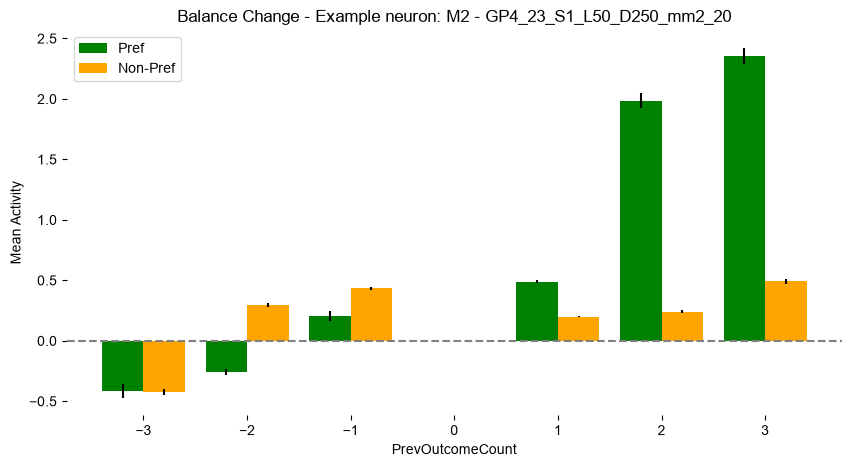

Trace GP4_23_S1_L50_D250_mm2_211 is not increasing
Trace GP4_23_S1_L50_D250_mm2_213 is not increasing
Trace GP4_23_S1_L50_D250_mm2_217 is not increasing


Trace GP4_23_S1_L50_D250_mm2_23 is not increasing
Trace GP4_23_S1_L50_D250_mm2_25 is not increasing
Trace GP4_23_S1_L50_D250_mm2_275 is not increasing
Trace GP4_23_S1_L50_D250_mm2_414 is not increasing
Trace GP4_23_S1_L50_D250_mm2_416 is not increasing
Trace GP4_23_S1_L50_D250_mm2_437 is not increasing
Trace GP4_23_S1_L50_D250_mm2_45 is not increasing
Trace GP4_23_S1_L50_D250_mm2_48 is not increasing
Trace GP4_23_S1_L50_D250_mm2_58 is not increasing
Trace GP4_23_S1_L50_D250_mm2_753 is not increasing
Trace GP4_23_S1_L50_D250_mm2_819 is not increasing
Trace GP4_23_S1_L50_D250_mm2_827 is not increasing
Trace GP4_23_S1_L50_D250_mm2_86 is not increasing
Trace GP4_23_S1_L50_D250_mm2_869 is not increasing
Trace GP4_23_S1_L50_D250_mm2_96 is not increasing
Trace GP4_23_S1_L50_D250_mm2_98 is not increasing
Trace GP4_23_s3_L50_D250_M2_156 is not increasing
Trace GP4_23_s3_L50_D250_M2_160 is not increasing
Trace GP4_23_s3_L50_D250_M2_173 is not increasing
Trace GP4_23_s3_L50_D250_M2_194 is not inc

In [ ]:
from .twop.balancechange import plotBalanceChangeSingleNeuron

plotBalanceChangeSingleNeuron(balance_df, save_figs=SAVE_FIGS,
                              fig_save_prefix=fig_save_prefix)

## Reward Rate

In [ ]:
from .twop import prevoutcomebalance as pb

# Per neuron and previous-outcome run length (twop/prevoutcomebalance.py).
# Row layout: a trace appears either under a data col, with pref/non-pref
# values and no "all" values, or under "All", with only "all" values.
balance_df_all = pb.makeBalanceDf(run_data_unnormalized[0].shortlong_df,
                                  expanded_df=normalized_expanded_df,
                                  pval=PVAL, max_outcome=pb.MAX_OUTCOME)

All traces


Data col: ChoiceLeft
   BrainRegion: 6


   BrainRegion: 15


Data col: IsEasy
   BrainRegion: 6


   BrainRegion: 15


Data col: PrevChoiceCorrect
   BrainRegion: 6


   BrainRegion: 15


Data col: PrevChoiceLeft
   BrainRegion: 6


   BrainRegion: 15


Data col: PrevIsEasy
   BrainRegion: 6


   BrainRegion: 15


In [ ]:
# No panel of this loop is in the paper (Figure 6C's example neuron is drawn by
# 2p_4_feedback.ipynb) -- so a paper-only run skips the loop rather than
# writing every neuron.
_sess_totals = {sess: sess_df.long_trace_id.nunique()
                for sess, sess_df in normalized_expanded_df.groupby("ShortName")}
stats_df = pb.incrementingStats(balance_df_all, sess_totals=_sess_totals,
                                plot=False,
                                save_figs=(SAVE_FIGS and not PAPER_FIGURES_ONLY),
                                fig_save_prefix=fig_save_prefix)
stats_df

In [ ]:
pb.printStats(stats_df, save_figs=False, fig_save_prefix=fig_save_prefix)

ALM
    All: 8/609 (1.34%) ± 0.56
    ChoiceLeft: 4/609 (0.93%) ± 0.55
    Global: 57/609 (9.79%) ± 2.09


    IsEasy: 2/609 (0.26%) ± 0.26
    PrevChoiceCorrect: 40/609 (6.84%) ± 1.40
    PrevChoiceLeft: 10/609 (1.67%) ± 0.48
    PrevIsEasy: 4/609 (0.66%) ± 0.34
M2
    All: 2/837 (0.30%) ± 0.24
    ChoiceLeft: 1/837 (0.05%) ± 0.05
    Global: 106/837 (15.25%) ± 3.87


    IsEasy: 0/837 (0.00%) ± 0.00
    PrevChoiceCorrect: 86/837 (12.51%) ± 3.65
    PrevChoiceLeft: 25/837 (3.07%) ± 1.03
    PrevIsEasy: 2/837 (0.31%) ± 0.31


# Cityscape Figure

In [ ]:
from functools import partial

from .twop.subpoptraces import choiceStats

_data_col = "ChoiceLeft"
# The choice-selective neurons of Figures 5E, 5F, S12D-J: significant for the
# current choice, no difficulty split, one row per neuron (unit-tested in
# twop/subpoptraces.py).
nonQuantiledStats = partial(choiceStats, pval=PVAL, data_col=_data_col)

## Current-Trial Left-vs-Right — Figure 5E

In [ ]:
from .twop.plottuning import samplingSlowVsFast, TrajectoryTuningPlot
# Treat warnings as errors
import warnings
# warnings.filterwarnings("error")
# Re-enable warnings
warnings.filterwarnings("default")




sep_side = False
def plotTrajectory(as_weight, weight_only_first_last, plot_region_trace,
                   plot_single_pts, plot_linear_fit=False,
                   combine_strategies=False, split_difficulties=False,
                   save_fig=False):
    combine_brain_regions = False
    stats_df = nonQuantiledStats(run_data_unnormalized[0].shortlong_df)
    dv_str_list = [None] if not split_difficulties else ["Easy", "Med", "Hard"]
    for dv_str in dv_str_list:
      for choice_outcome, choice_descrp in [(None, "both correct and incorrect"),
                                            #(True, "Correct"),
                                            #(False, "Incorrect"),
                                            ]:
        for prev_choice_outcome, prev_choice_descrp in [(None, ""),
                                                        #(True, "previous correct trials"),
                                                        #(False, "previous incorrect trials"),
                                                        ]:
          for combine_sides in [True,
                                #False
                                ]:

            label = f"Hist Choice ZScored Where Choices are {choice_descrp}"
            sub_norm_expanded_df = normalized_expanded_df
            if choice_outcome is not None:
              sub_norm_expanded_df = sub_norm_expanded_df[sub_norm_expanded_df.ChoiceCorrect == choice_outcome]
            label += " sides combined" if combine_sides else " sides separated"
            if dv_str in ["Easy", "Med", "Hard"]:
              label = f"{label} for only {dv_str} trials"
              sub_norm_expanded_df = sub_norm_expanded_df[sub_norm_expanded_df.DVstr == dv_str]
            else:
              label = f"{label} for all difficulties"
            #
            if prev_choice_outcome is not None:
              label = f"{label} for {prev_choice_descrp}"
              sub_norm_expanded_df = sub_norm_expanded_df[sub_norm_expanded_df.PrevChoiceCorrect == prev_choice_outcome]
            skip_qidx2 = True
            y_lim = (-50, 200) if as_weight else (None, None)
            combine_in_single_plot = as_weight and weight_only_first_last
            if as_weight and weight_only_first_last and not combine_sides:
              combine_in_single_plot = False # Not supported with separated sides

            tuning_plotter = TrajectoryTuningPlot(method="mean",
                                                  combine_in_single_plot=combine_in_single_plot,
                                                  skip_qidx2=skip_qidx2,
                                                  combine_sides=combine_sides,
                                                  combine_brain_regions=combine_brain_regions,
                                                  plot_all=combine_strategies,
                                                  plt_is_no_quantiles=combine_strategies,
                                                  plot_non_sgf=plot_region_trace,
                                                  y_lims=y_lim,
                                                  label=label, plot_sem=True,
                                                  bins_count=BINS_COUNT,
                                                  neuronFiringBinFn=neurons_iqr_df_all_trials,
                                                  as_weight=as_weight,
                                                  plot_weight_only_first_last=weight_only_first_last,
                                                  plt_single_pts=plot_single_pts,
                                                  plt_linear_fit=plot_linear_fit)
            extra_kwargs = dict(iter_col=None) if combine_strategies else dict()
            samplingSlowVsFast(stats_df=stats_df.copy(),
                                src_activitiy_df=sub_norm_expanded_df.copy(),
                                tuning_plotter=tuning_plotter,
                                sep_brain_region=not combine_brain_regions,
                                sep_side=not combine_sides,
                                left_tune_col="IsROCLeftTuend", pval=PVAL,
                                skip_qidx2=skip_qidx2,
                                data_col=_data_col,
                                sep_2_groups_col=_data_col,
                                fig_save_prefix=fig_save_prefix,
                                save_fig=save_fig,
                                **extra_kwargs)


is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


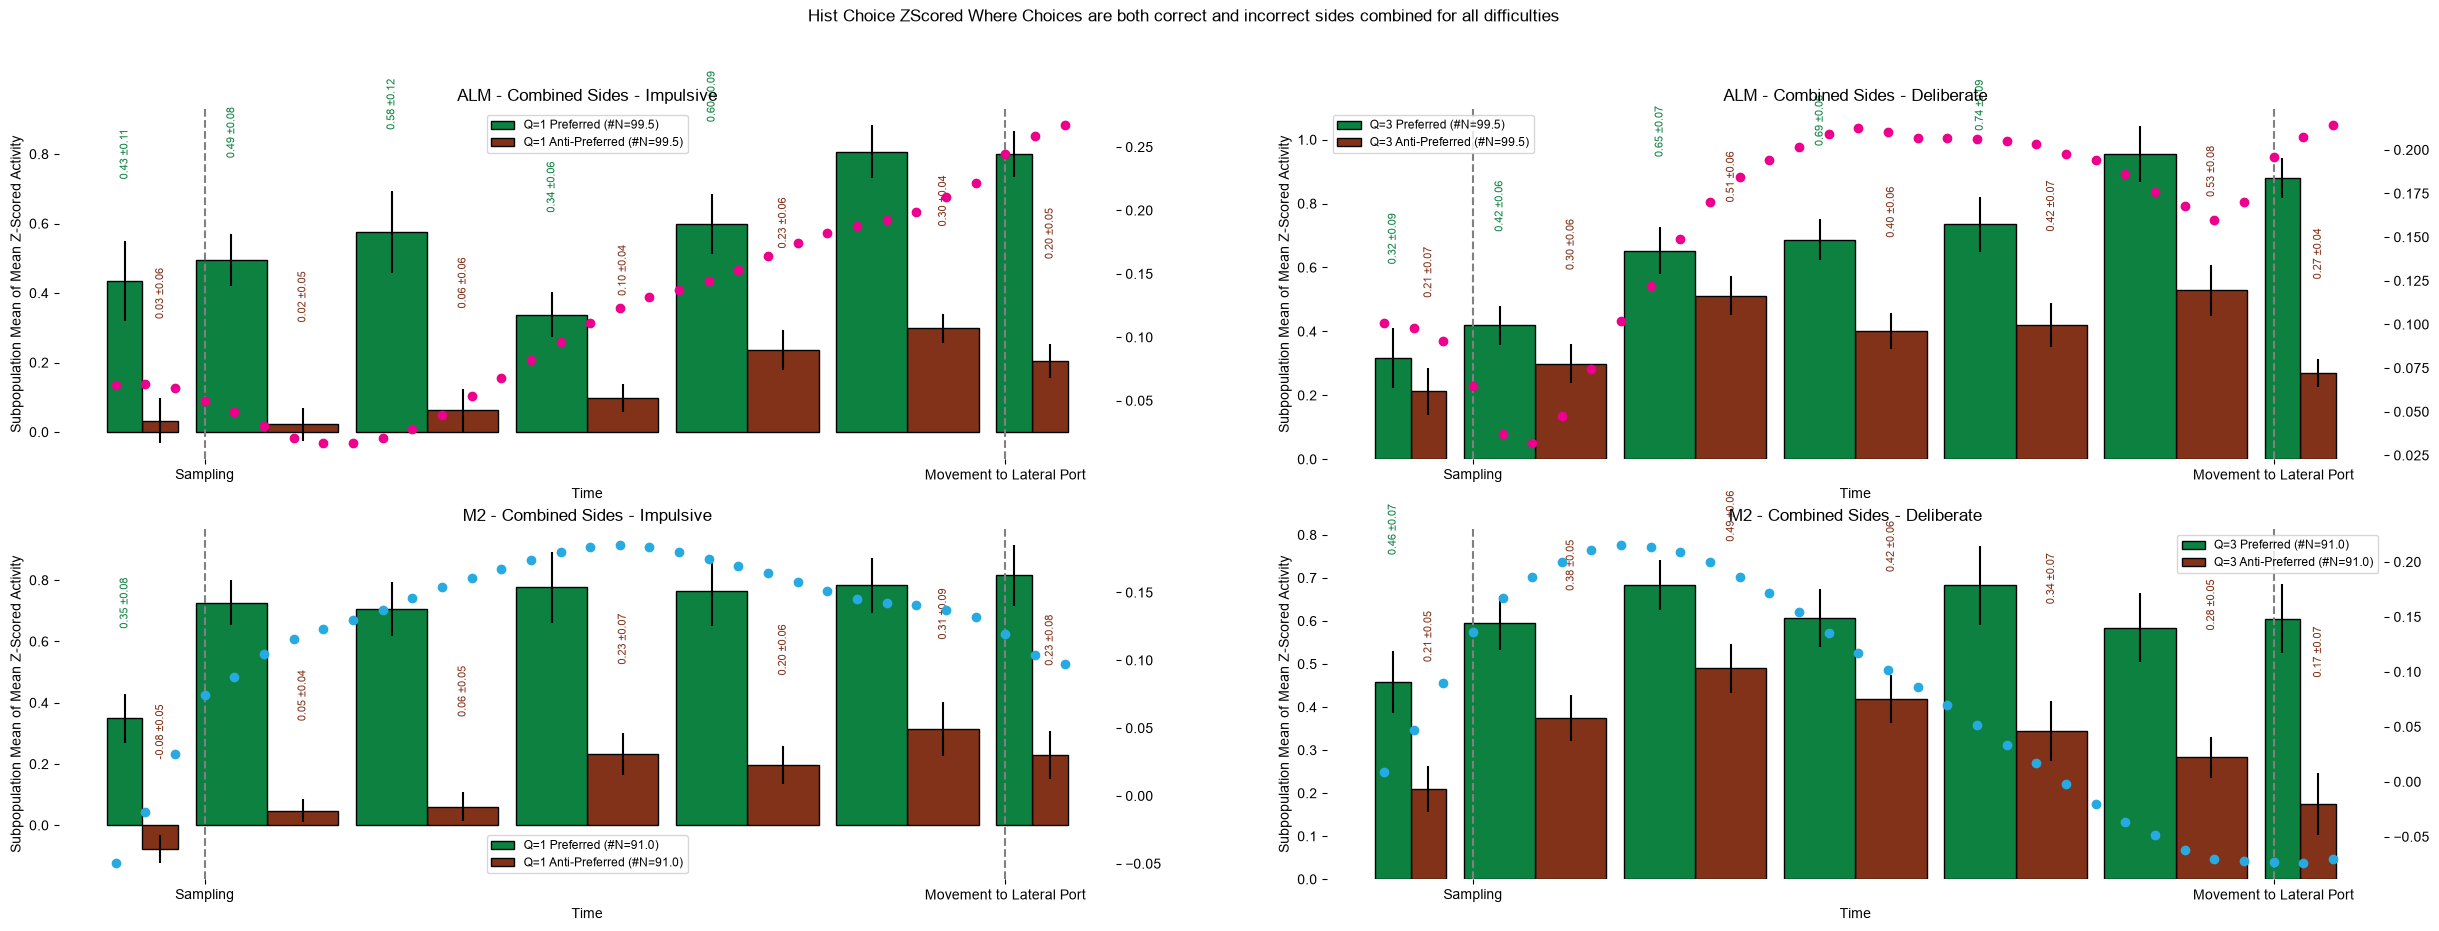

In [ ]:
plotTrajectory(as_weight=False, weight_only_first_last=False, plot_region_trace=True,
               plot_single_pts=False, plot_linear_fit=False, save_fig=SAVE_FIGS)

### Figure 5F

is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


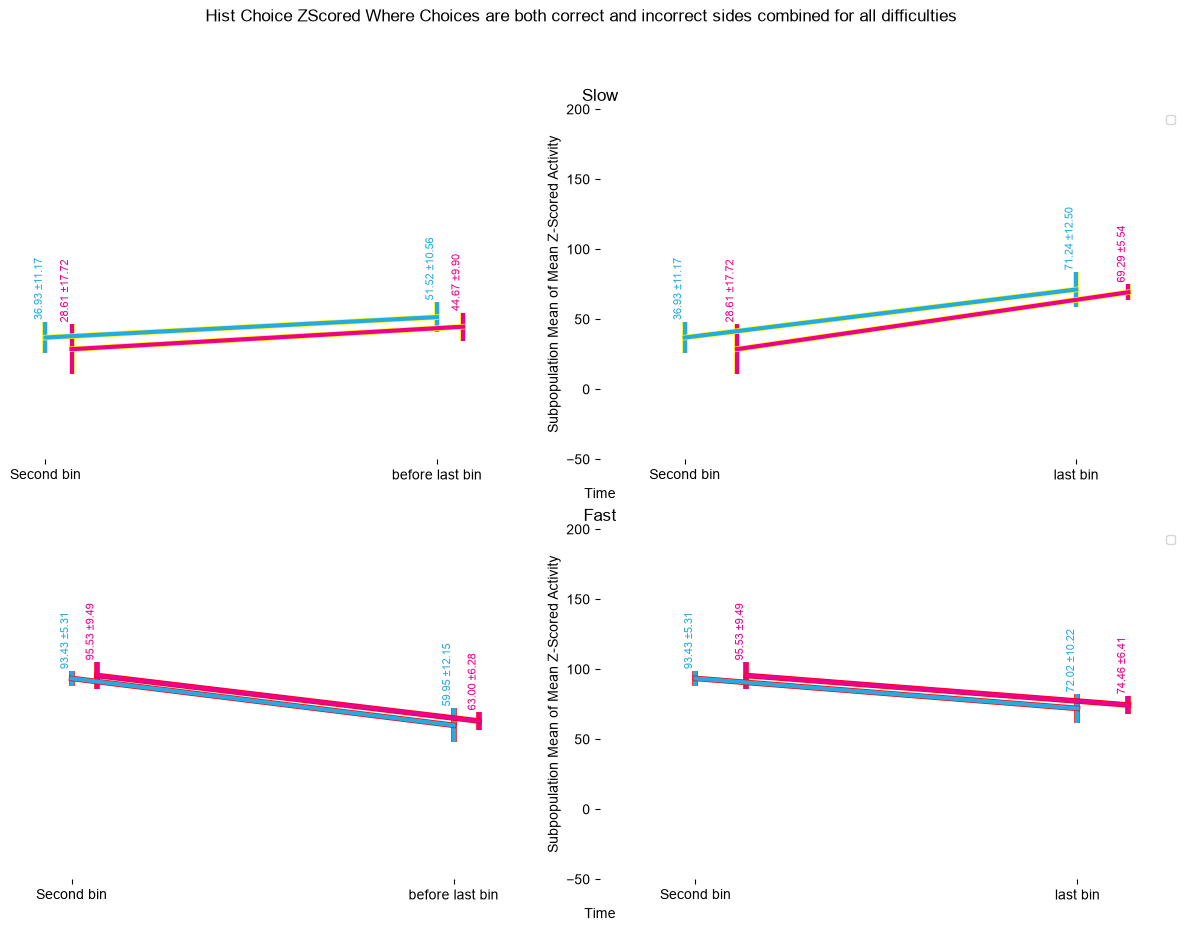

In [ ]:
plotTrajectory(as_weight=True, weight_only_first_last=True, plot_single_pts=False,
               # Here these are irrelevant
               plot_region_trace=False,
               plot_linear_fit=False,
               #
               save_fig=SAVE_FIGS)

### Figure S12F

is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


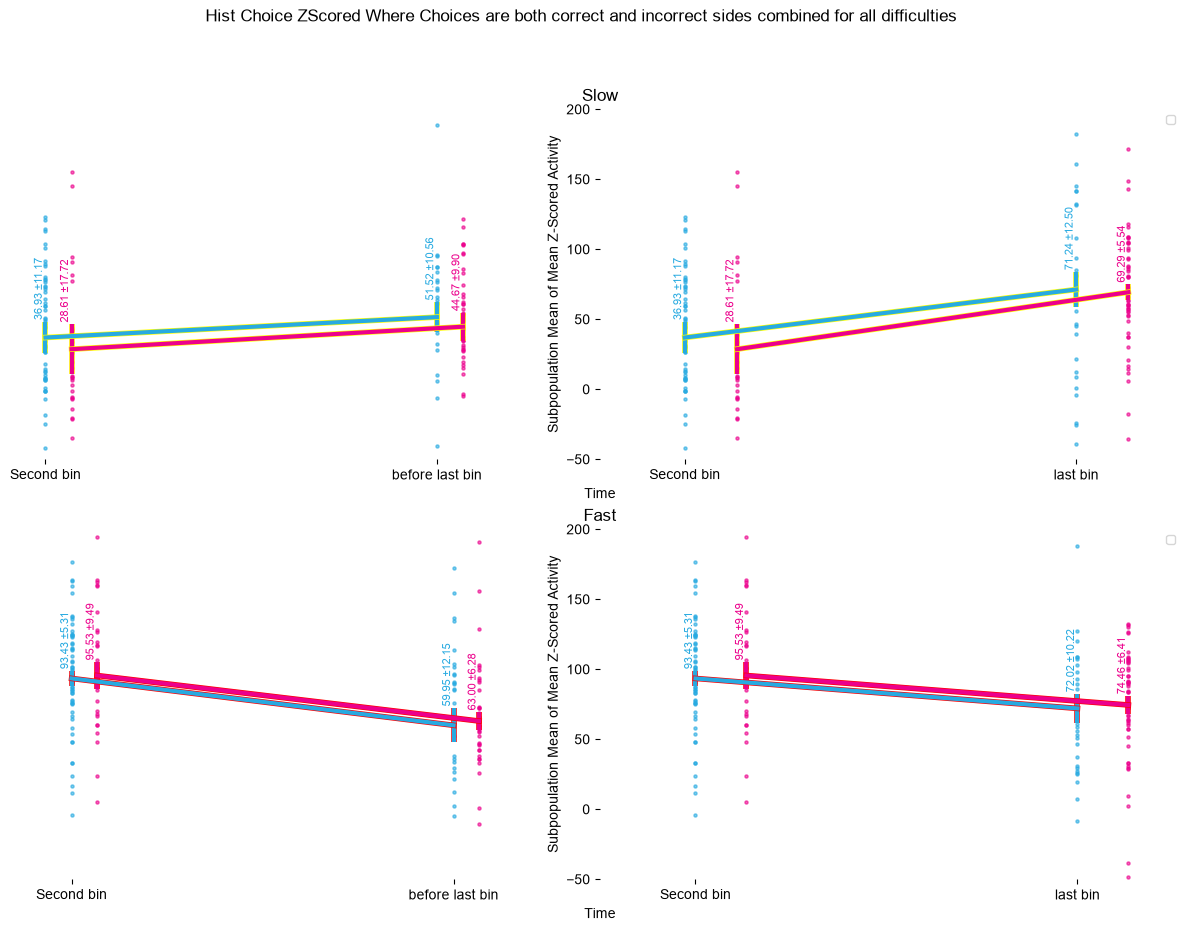

In [ ]:
plotTrajectory(as_weight=True, weight_only_first_last=True, plot_single_pts=True,
               # Here these are irrelevant
               plot_region_trace=False,
               plot_linear_fit=False,
               #
               save_fig=SAVE_FIGS)

### Figure S12E

is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


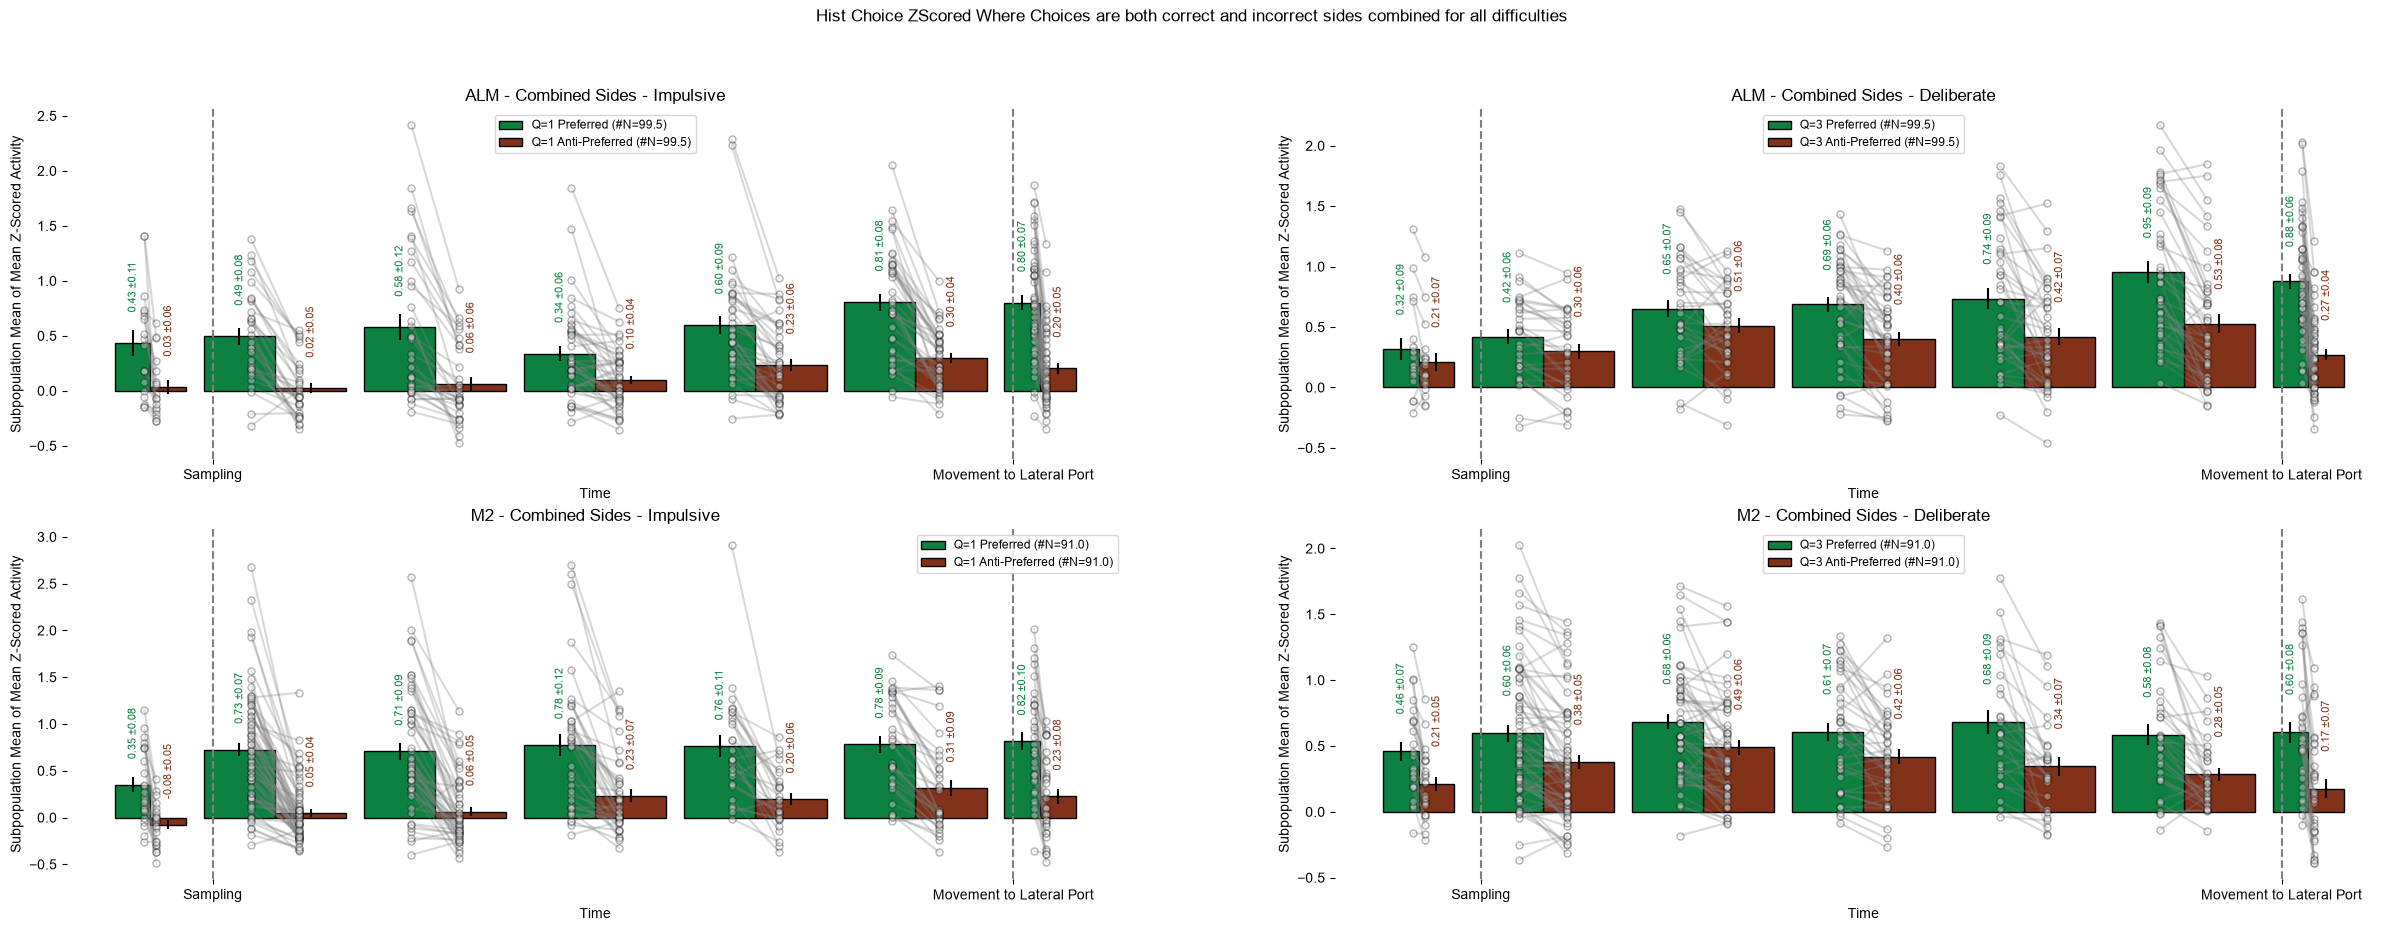

In [ ]:
plotTrajectory(plot_single_pts=True, as_weight=False, weight_only_first_last=False,
               plot_region_trace=False, plot_linear_fit=False,  save_fig=SAVE_FIGS)

### Figure S12I

is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


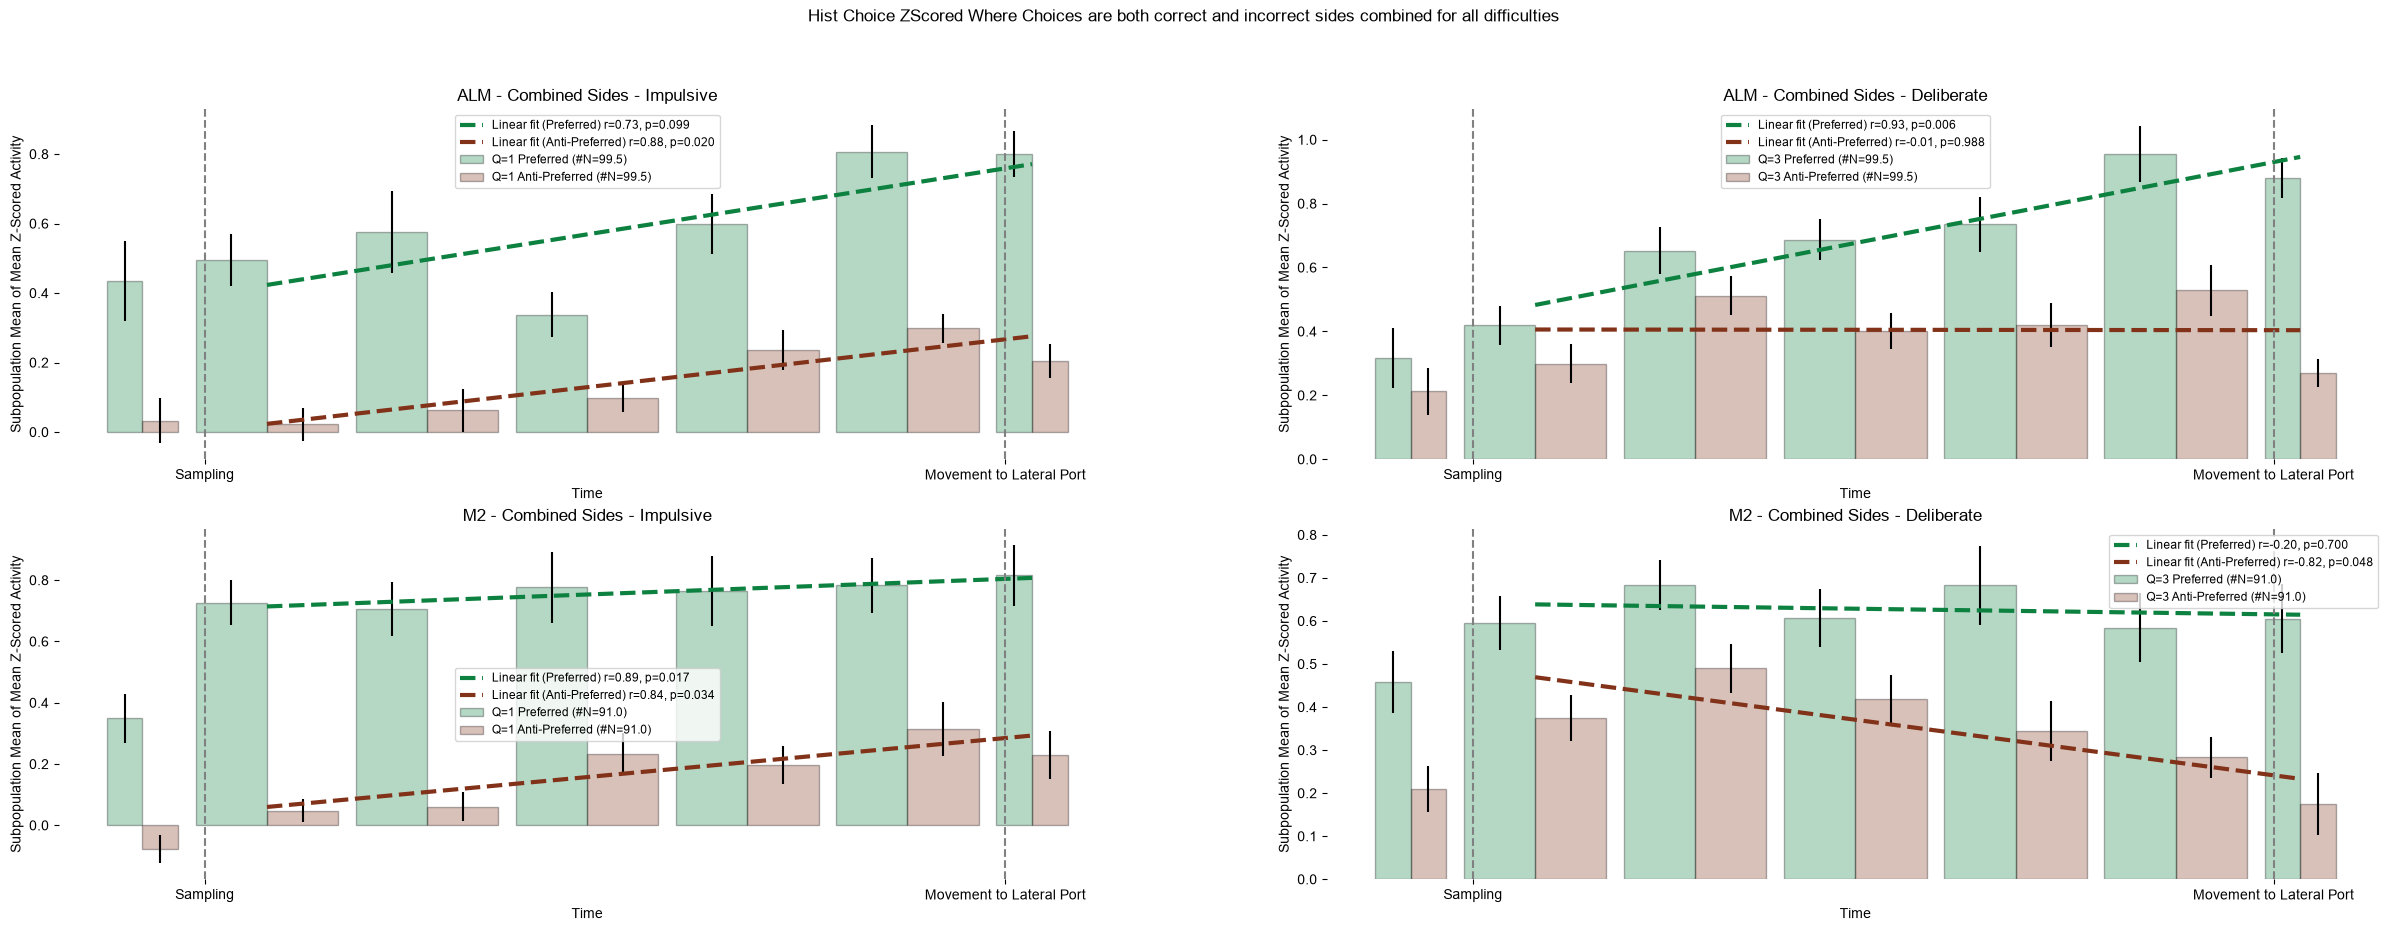

In [ ]:
plotTrajectory(plot_linear_fit=True, plot_single_pts=False, as_weight=False,
               weight_only_first_last=False, plot_region_trace=False, save_fig=SAVE_FIGS)

### Split by difficulty (not in the final paper)

is_left_choice_tuned
NaN    35585
1.0     7149
0.0     6823
Name: count, dtype: int64

is_left_choice_tuned
NaN    35369
1.0     7106
0.0     6824
Name: count, dtype: int64

is_left_choice_tuned
NaN    35434
1.0     7130
0.0     6807
Name: count, dtype: int64

Len preferred_dir_df: 1760 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 1672 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2144 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 1397 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 1333 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 2111 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 1567 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 1659 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


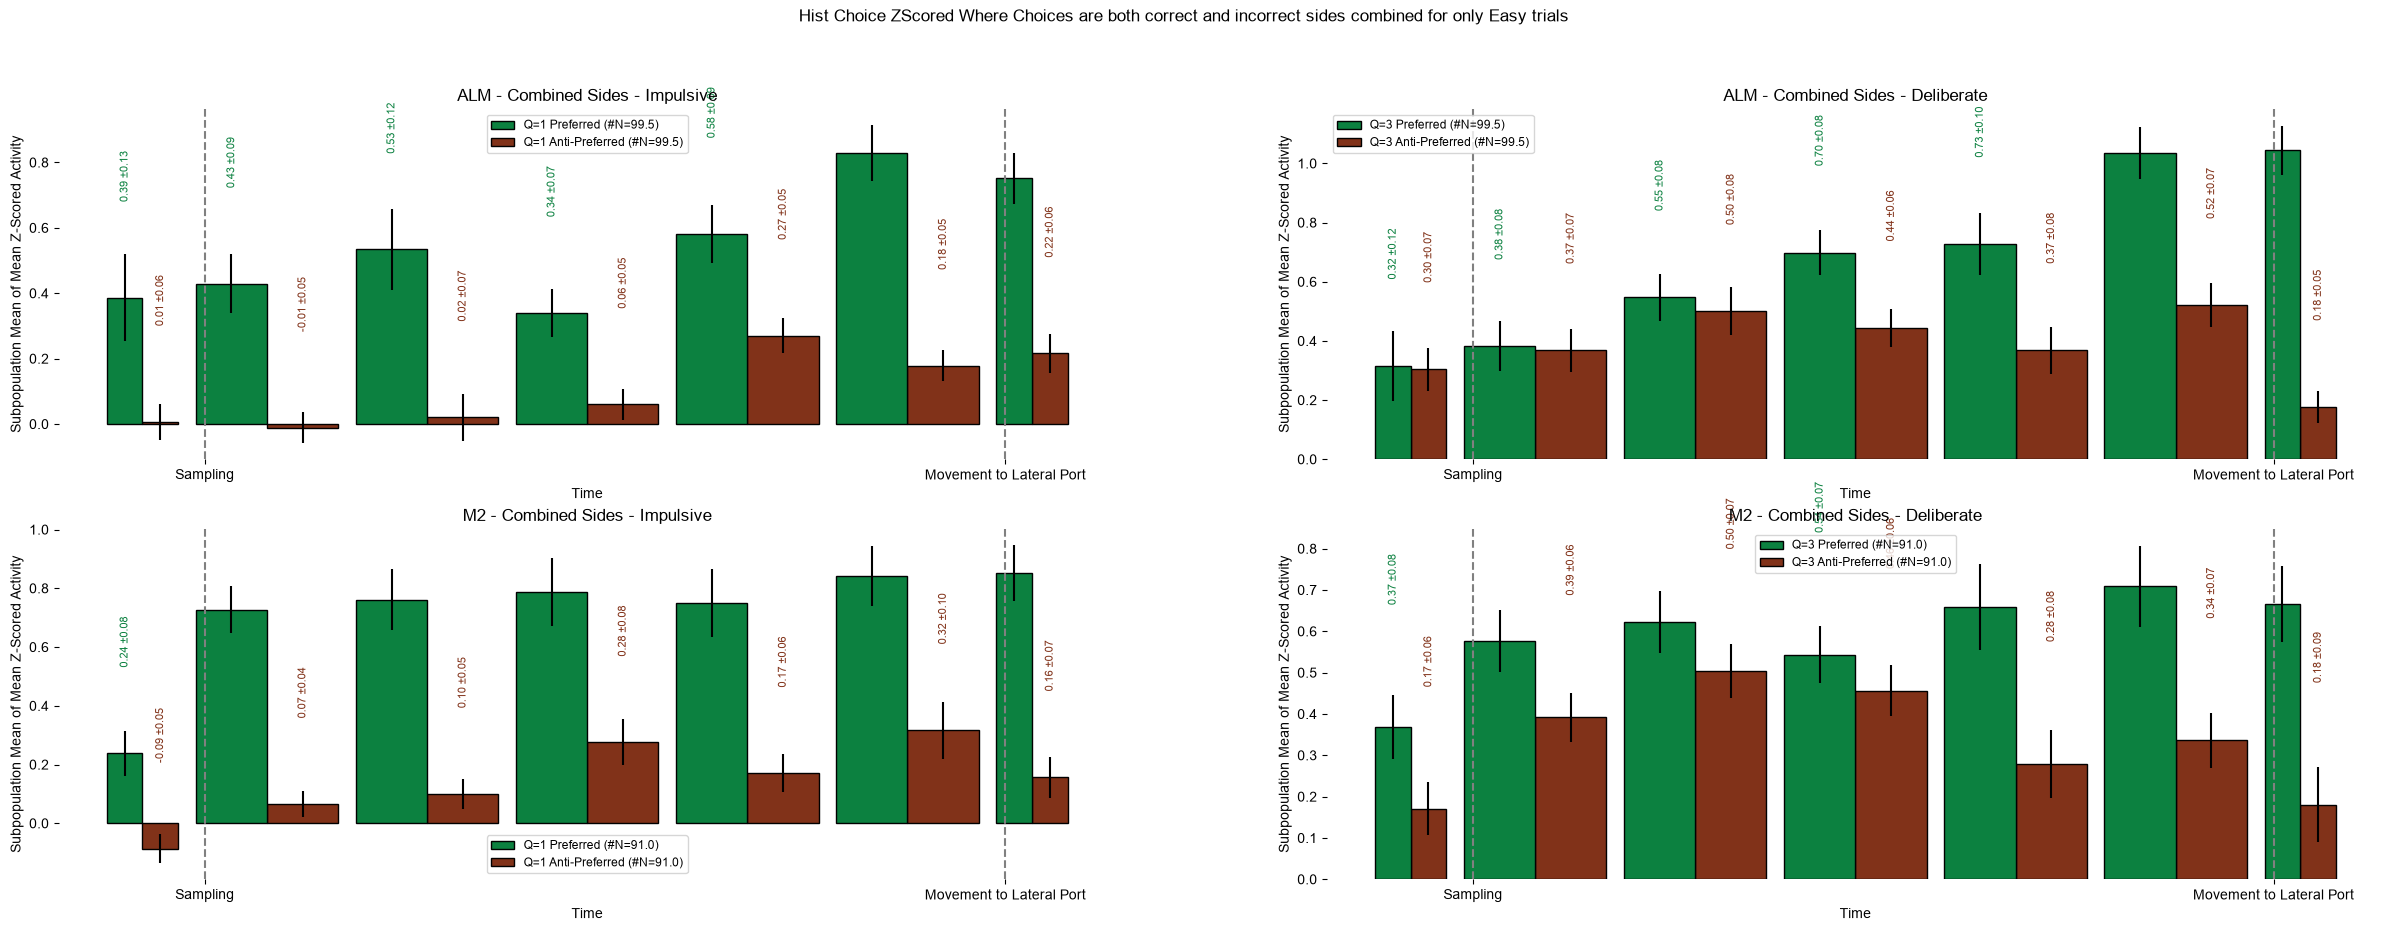

is_left_choice_tuned
NaN    28719
1.0     5377
0.0     5358
Name: count, dtype: int64

is_left_choice_tuned
NaN    28953
1.0     5415
0.0     5369
Name: count, dtype: int64

is_left_choice_tuned
NaN    28645
1.0     5382
0.0     5365
Name: count, dtype: int64

Len preferred_dir_df: 1300 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 1426 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2004 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 941 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 937 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 1688 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 1066 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 1451 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


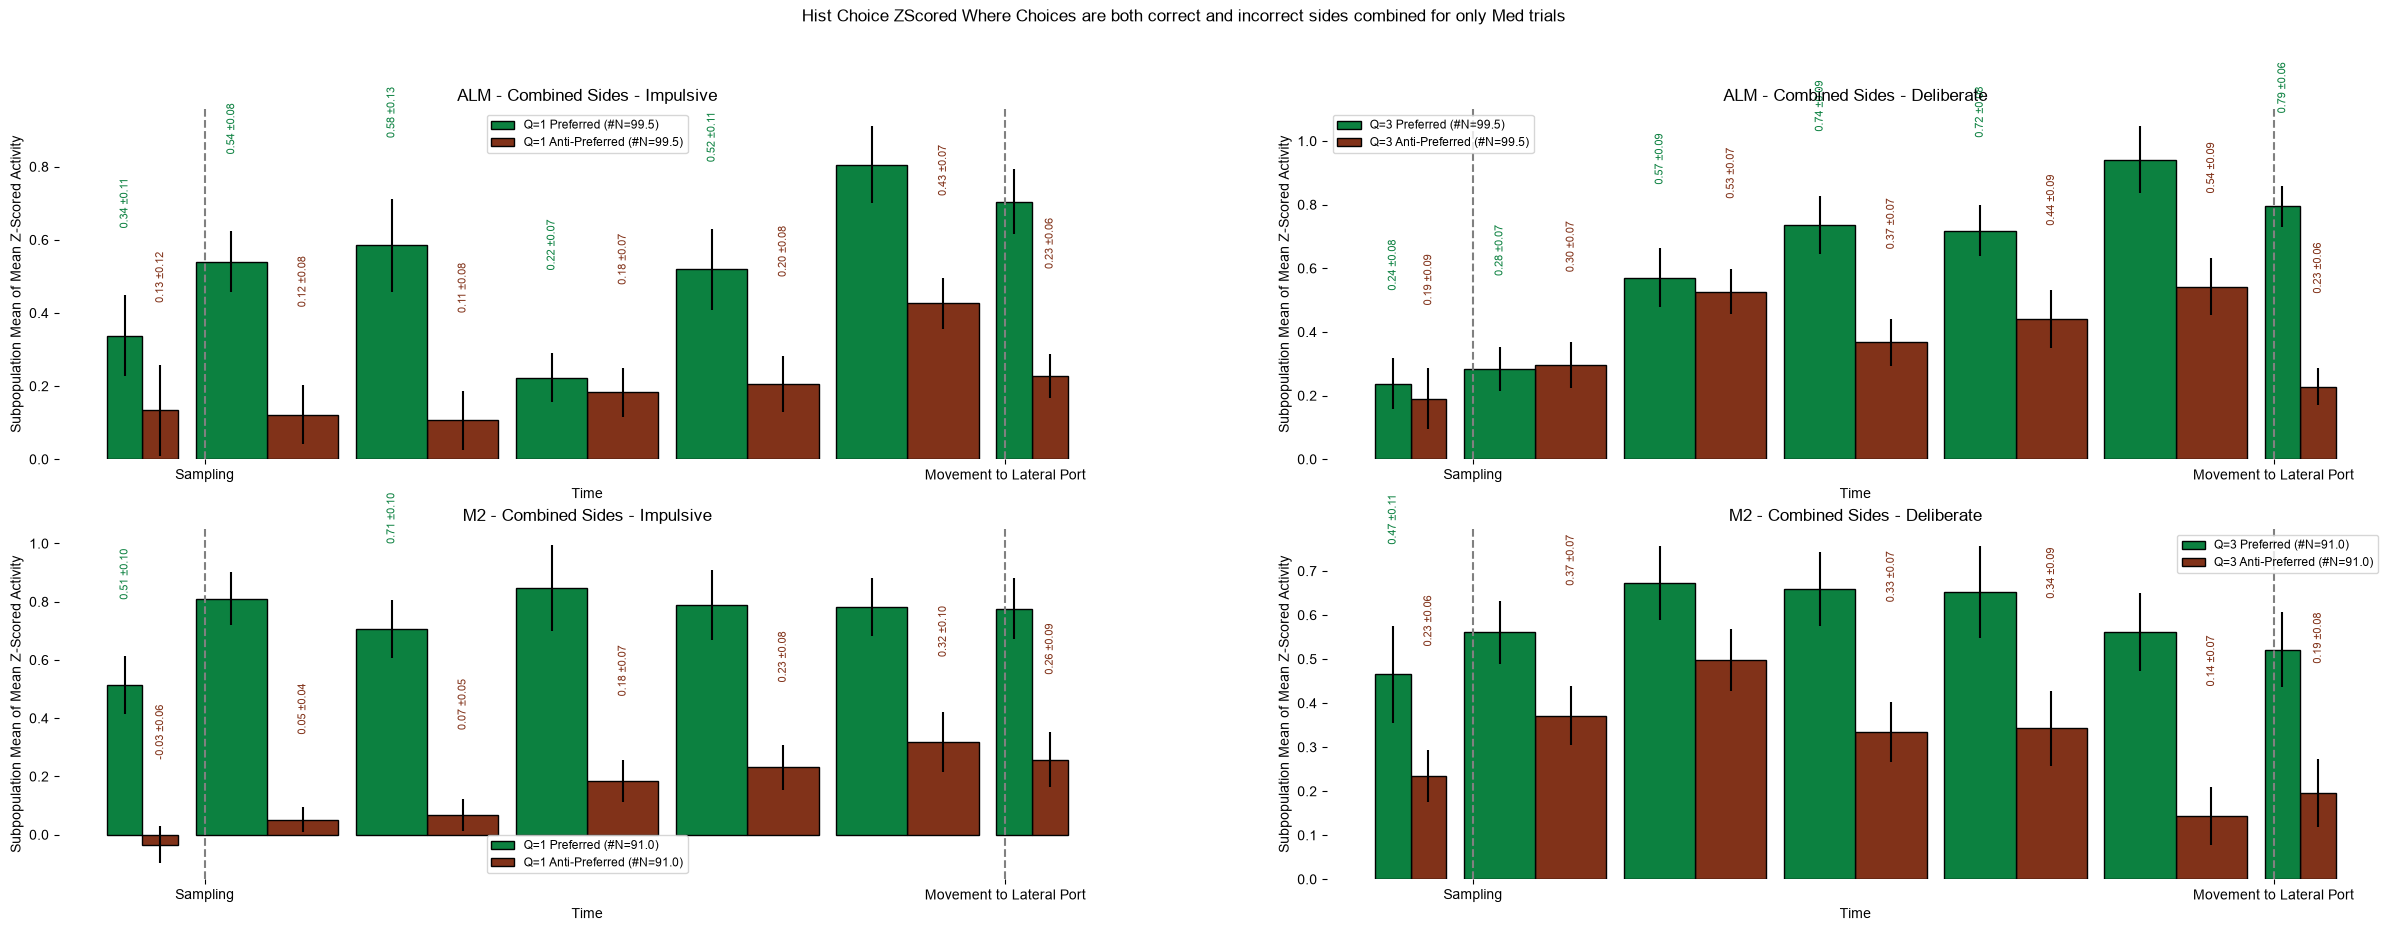

is_left_choice_tuned
NaN    19736
1.0     3674
0.0     3494
Name: count, dtype: int64

is_left_choice_tuned
NaN    19677
1.0     3653
0.0     3470
Name: count, dtype: int64

is_left_choice_tuned
NaN    19848
1.0     3658
0.0     3476
Name: count, dtype: int64

Len preferred_dir_df: 1049 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 700 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 1127 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 704 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 707 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 963 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 773 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 876 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


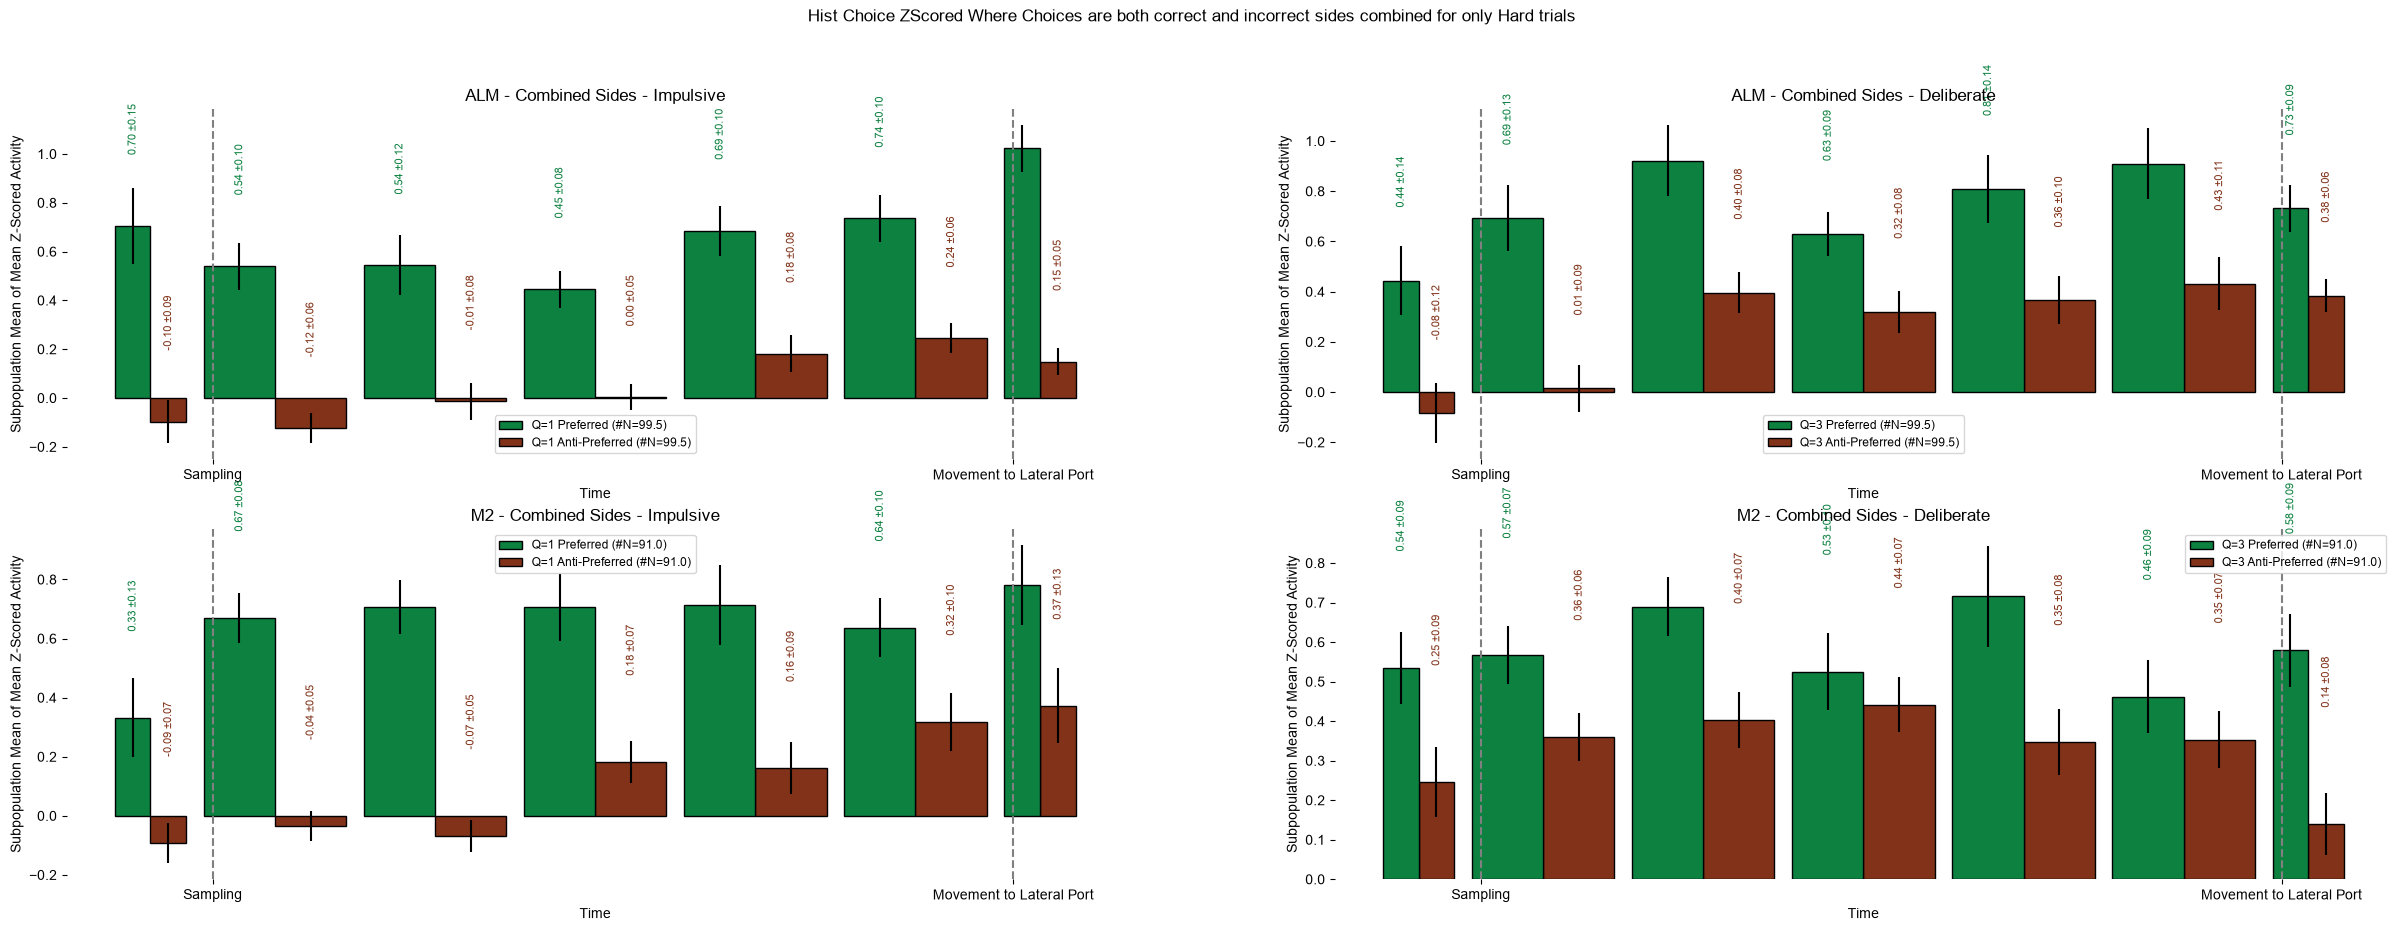

In [ ]:
plotTrajectory(split_difficulties=True,
               plot_single_pts=False, as_weight=False, weight_only_first_last=False,
               plot_region_trace=False, plot_linear_fit=False, save_fig=SAVE_FIGS)

### Figure S12H

is_left_choice_tuned
NaN    84040
1.0    16200
0.0    15675
Name: count, dtype: int64

is_left_choice_tuned
NaN    83999
1.0    16174
0.0    15663
Name: count, dtype: int64

is_left_choice_tuned
NaN    83927
1.0    16170
0.0    15648
Name: count, dtype: int64

Len preferred_dir_df: 4109 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3798 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 5275 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 120
Len preferred_dir_df: 3042 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 79
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 2977 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 4762 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 0 Choice dir: None last_dir: -1
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


Len preferred_dir_df: 3406 for choice_dir: 1.0 For sour split: ChoiceLeft uniq traces: 77
Len preferred_dir_df: 3986 for choice_dir: 0.0 For sour split: ChoiceLeft uniq traces: 105
Col idx: 1 Choice dir: None last_dir: None
Rounded to: [ 0.   3.   8.4 13.8 19.2 24.6 30.  33. ]


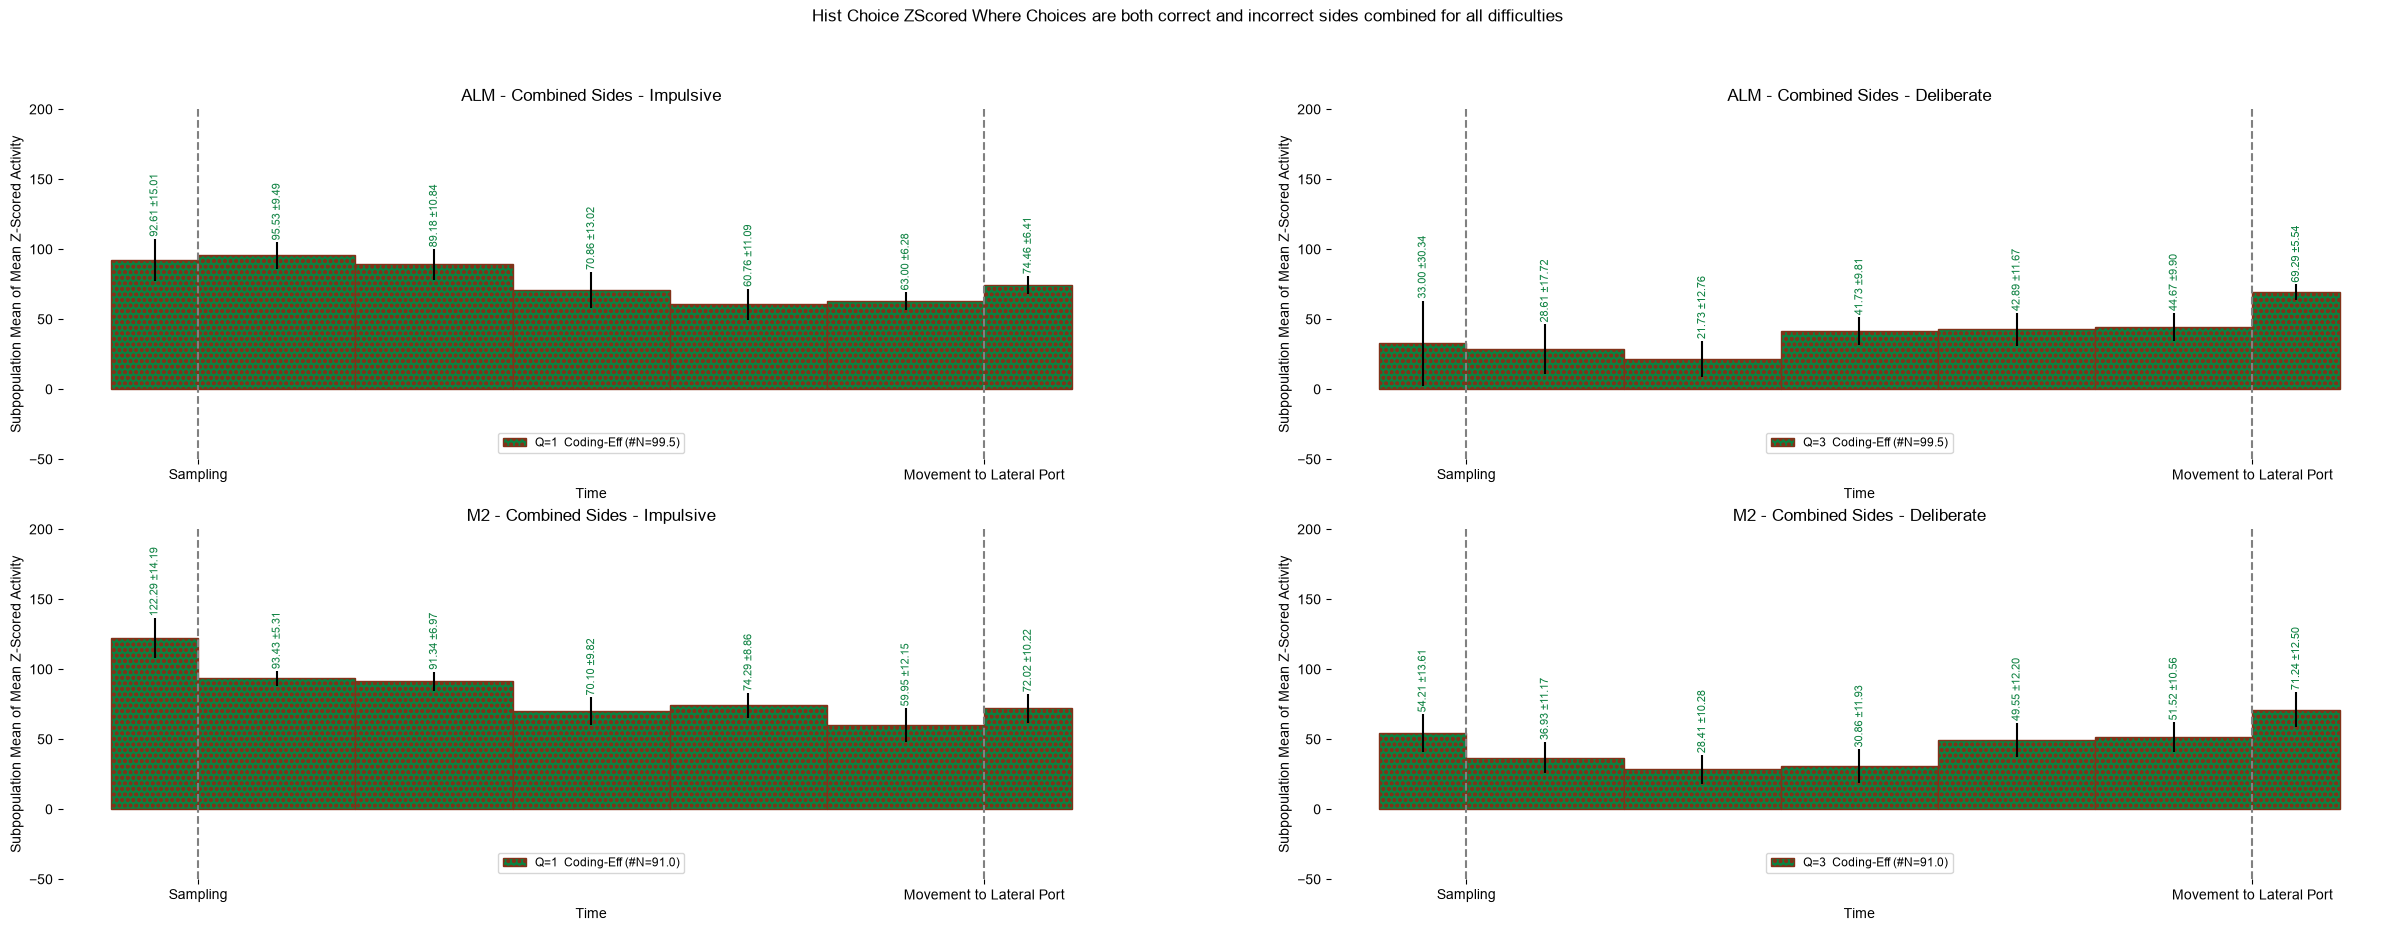

In [ ]:
plotTrajectory(as_weight=True, weight_only_first_last=False,  plot_region_trace=False,
               plot_linear_fit=False, plot_single_pts=False, save_fig=SAVE_FIGS)

### Figure S12D (bottom) — the first and last sampling bins' neurons in real time

In [ ]:
from .twop import subpoptraces as sp
from .twop.dataload import loadSamplingUnnormalized

# The neurons of the first and of the last sampling bar of S12E (top of S12D),
# on matched vs mismatched, fast vs slow trials, aligned to sampling onset.
sp.plotSequenceEndsTraces(loadSamplingUnnormalized(),
                          nonQuantiledStats(run_data_unnormalized[0].shortlong_df),
                          neurons_iqr_df_all_trials,
                          epoch_ranges=normed_sampling_df.iloc[0].epochs_ranges,
                          pval=PVAL, save_figs=SAVE_FIGS,
                          fig_save_prefix=fig_save_prefix);

# The same with correct trials only, saved under *_correct_trials.
sp.plotSequenceEndsTraces(loadSamplingUnnormalized(),
                          nonQuantiledStats(run_data_unnormalized[0].shortlong_df),
                          neurons_iqr_df_all_trials,
                          epoch_ranges=normed_sampling_df.iloc[0].epochs_ranges,
                          pval=PVAL, save_figs=SAVE_FIGS,
                          fig_save_prefix=fig_save_prefix, correct_only=True);

# Movement time neurons

## Movement-time neurons: MFC vs LFC — Figure S12J (left)

A neuron's firing position is the **median** of its per-trial peak samples
(`max_idxs`, built in the `# Sequence Extraction` section). The sampling-aligned
traces carry `epochs_ranges = [(0, 2), (3, 29), (30, 32)]` =
`['-0.1s Sampling', 'Sampling', 'Movement to Lateral Port']`, and with
`BINS_COUNT = 7` the bins are `[pre-sampling] + 5 x [sampling] + [movement]`, so
the **last (7th) bin `(30, 33]` is the movement epoch** and the **6th bin
`(24.6, 30]` is where movement is initiated** - the last ~0.18 s of sampling
before the animal leaves the centre port, which is exactly the window
`makeActive` selects its own "movement" set on. Each method below is a
*criterion* x *window* pair:

- **`last_bin`** - median peak in the last bin (movement only). `maxFiringHist`
  bins with `pd.cut`, whose intervals are left-open, so a median sitting exactly
  on the onset sample (30) counts as the last *sampling* bin.
- **`last_two_bins`** - median peak in the last **two** bins, i.e. movement
  initiation **or** movement. A superset of `last_bin`.
- **`movement_epoch`** - median peak `>=` the movement onset. The same question
  read straight off `epochs_ranges`, the way `_setupAxs` / `makeActive` do;
  it differs from `last_bin` only for the medians exactly on sample 30.
- **`iqr_q1`** - stricter, and built the way `makeActive` picks its neuron sets:
  the **q1** of the per-trial peaks is `>=` the onset, i.e. the neuron peaks
  after movement start in >=75% of its active trials, not merely in the median
  trial.

`METHOD_SPECS` also registers `initiation_onset` and `iqr_q1_two_bins` (the
threshold and q1 criteria on the two-bin window); pass them via `methods=` to
run those too.

Each criterion is reported twice: over **all** neurons, and restricted to the
neurons that are *also* significantly choice-selective (`getSgfNeurons`,
`data_col="ChoiceLeft"`, no prior, `pval <= PVAL`) - still as a percentage of
**all** neurons, so the two numbers are directly comparable. (Choice-selectivity
on its own, with no movement restriction, is not repeated here - it is the
number the `# Sgf. Neurons Pie Charts` section already plots; it stays in the
per-session table as `n_choice` / `prcnt_choice` because it feeds the
intersection.) Percentages are
**mean +/- SEM over sessions** (the session is the independent unit, as in the
pie-chart / Venn sections), each session's denominator being all of its neurons.
MFC vs LFC runs a **normality test first**: Shapiro-Wilk on each region's
per-session values (the two regions are independent samples of *different*
sessions, so there are no paired differences to test). If both look normal the
comparison is a **two-sample t-test**, with Levene's test picking Student
(equal variances) vs Welch; otherwise it falls back to **Mann-Whitney U**, the
notebook's `defaultStatsTestFn`. Both p-values are always reported
(`ttest_pval`, `mwu_pval`), with `test` / `statistic` / `pval` carrying the one
the gate selected.

Because sessions are **nested in a handful of animals** (MFC 5 animals / 13
sessions, LFC only **3** animals / 10 sessions, with an intra-class correlation
of 0.35-0.64), a session-level test can be carried by repeated sessions of one
animal. The last cell therefore re-tests every comparison with a **hierarchical
bootstrap** (resample animals -> that animal's sessions -> the neurons within
each session, 10k times) and reports the bootstrap SE, the 95% CI of the
MFC-LFC difference and a direct-probability p. Read a result as solid only when
both agree. All the code lives in `twop/movementneurons.py`.

In [ ]:
from .twop import movementneurons as mn

def runMovementNeurons(max_firing_df, normed_sampling_df, shortlong_df):
    """Per-session movement-neuron counts + the MFC-vs-LFC summary table."""
    # Choice-selective = sgf. for the current-trial direction, no prior, at PVAL.
    choice_sgf_ids = getSgfNeurons(shortlong_df, data_col="ChoiceLeft")
    sess_df = mn.perSessionCountsAllMethods(
        max_firing_df, epoch_ranges=normed_sampling_df.iloc[0].epochs_ranges,
        choice_sgf_ids=choice_sgf_ids, bins_count=BINS_COUNT)
    # prcnt_choice (choice-selectivity with NO movement restriction) is left out:
    # it is the same per-session mean +/- SEM that the "Sgf. Neurons Pie Charts"
    # section already plots. It stays in sess_df as n_choice / prcnt_choice.
    summary_df = mn.regionSummary(sess_df,
                                  metrics=(mn.METRIC_MOVEMENT,
                                           mn.METRIC_MOVEMENT_CHOICE,
                                           mn.METRIC_CHOICE_OF_MOVEMENT))
    print(mn.formatSummary(summary_df, bins_count=BINS_COUNT))
    return sess_df, summary_df

movement_sess_df, movement_summary_df = runMovementNeurons(
    max_firing_all_df, normed_sampling_df,
    run_data_unnormalized[0].shortlong_df)
display(movement_summary_df.round(2))

Movement-time neurons (% of all neurons)  [median peak during movement bin]
    MFC: 3.39% +/- 0.81% SEM  (13 sessions, 25/837 neurons)
    LFC: 6.43% +/- 2.05% SEM  (10 sessions, 46/609 neurons)
    Normality (Shapiro-Wilk): MFC p=0.354, LFC p=0.0936 -> normal, t-test usable
    MFC vs LFC: t-test (Welch) stat=-1.38, p=0.193 (MannWhitneyU p=0.332 for reference)
Movement-time AND choice-selective neurons (% of all neurons)  [median peak during movement bin]
    MFC: 1.75% +/- 0.56% SEM  (13 sessions, 13/837 neurons)
    LFC: 3.11% +/- 1.09% SEM  (10 sessions, 21/609 neurons)
    Normality (Shapiro-Wilk): MFC p=0.00933, LFC p=0.0727 -> not normal, t-test not usable
    MFC vs LFC: MannWhitneyU stat=54, p=0.502 (t-test p=0.252 for reference)
Choice-selective neurons (% of movement-time neurons)  [median peak during movement bin]
    MFC: 55.33% +/- 13.29% SEM  (10 sessions, 13/25 neurons)
    LFC: 45.82% +/- 12.22% SEM  (7 sessions, 21/46 neurons)
    Normality (Shapiro-Wilk): MFC p=0.04

,method,metric,MFC_n_sessions,MFC_mean,MFC_sem,MFC_n,MFC_total,LFC_n_sessions,LFC_mean,LFC_sem,...,MFC_shapiro_pval,LFC_shapiro_W,LFC_shapiro_pval,is_normal,levene_pval,test,statistic,pval,ttest_pval,mwu_pval
0,last_bin,prcnt_movement,13,3.39,0.81,25,837,10,6.43,2.05,...,0.35,0.87,0.09,True,0.02,t-test (Welch),-1.38,0.19,0.19,0.33
1,last_bin,prcnt_movement_choice,13,1.75,0.56,13,837,10,3.11,1.09,...,0.01,0.86,0.07,False,0.09,MannWhitneyU,54.00,0.50,0.25,0.50
2,last_bin,prcnt_choice_of_movement,10,55.33,13.29,13,25,7,45.82,12.22,...,0.05,0.94,0.68,False,0.26,MannWhitneyU,38.00,0.80,0.62,0.80
3,last_two_bins,prcnt_movement,13,15.91,1.58,127,837,10,24.12,3.61,...,0.05,0.99,0.99,False,0.05,MannWhitneyU,34.00,0.06,0.03,0.06
4,last_two_bins,prcnt_movement_choice,13,5.10,1.02,38,837,10,11.85,1.50,...,0.75,0.96,0.82,True,0.49,t-test (Student),-3.84,0.00,0.00,0.00
5,last_two_bins,prcnt_choice_of_movement,13,32.26,5.70,38,127,10,56.44,7.68,...,0.67,0.91,0.29,True,0.45,t-test (Student),-2.59,0.02,0.02,0.03
6,movement_epoch,prcnt_movement,13,5.56,0.93,43,837,10,9.45,3.58,...,0.70,0.83,0.04,False,0.02,MannWhitneyU,57.50,0.66,0.32,0.66
7,movement_epoch,prcnt_movement_choice,13,2.28,0.71,17,837,10,4.07,1.46,...,0.01,0.85,0.06,False,0.13,MannWhitneyU,54.00,0.50,0.25,0.50
8,movement_epoch,prcnt_choice_of_movement,11,43.48,11.73,17,43,7,44.44,11.83,...,0.14,0.97,0.86,True,0.22,t-test (Student),-0.05,0.96,0.96,0.96
9,iqr_q1,prcnt_movement,13,0.63,0.25,5,837,10,3.11,1.16,...,0.00,0.82,0.02,False,0.01,MannWhitneyU,39.00,0.09,0.06,0.09


In [ ]:
# The raw per-session counts behind the percentages (one row per session x
# criterion). n_neurons is the denominator of every prcnt_* except
# prcnt_choice_of_movement, which is out of that session's movement neurons.
display(movement_sess_df.sort_values(["method", "BrainRegion", "ShortName"]))

,method,BrainRegion,ShortName,animal,n_neurons,n_movement,n_choice,n_movement_choice,prcnt_movement,prcnt_movement_choice,prcnt_choice,prcnt_choice_of_movement
69,iqr_q1,LFC,GP4_23_s6_L50_D250_ALM,GP4_23,77,7,14,1,9.090909,1.298701,18.181818,14.285714
70,iqr_q1,LFC,GP4_23_s7_L50_D250_ALM,GP4_23,106,3,39,2,2.830189,1.886792,36.792453,66.666667
71,iqr_q1,LFC,GP4_23_s8_L50_D250_ALM,GP4_23,94,3,44,2,3.191489,2.127660,46.808511,66.666667
72,iqr_q1,LFC,GP4_85_s10_L70_D250_ALM,GP4_85,38,0,16,0,0.000000,0.000000,42.105263,NaN
73,iqr_q1,LFC,GP4_85_s6_L65_D250_ALM,GP4_85,60,1,21,1,1.666667,1.666667,35.000000,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
64,movement_epoch,MFC,GP4_80_S2_L51_D250_M2m,GP4_80,54,4,5,3,7.407407,5.555556,9.259259,75.000000
65,movement_epoch,MFC,GP4_80_S4_L50_D250_M2m,GP4_80,45,5,10,3,11.111111,6.666667,22.222222,60.000000
66,movement_epoch,MFC,GP4_85_S1_L70_D250_mm2,GP4_85,50,3,5,2,6.000000,4.000000,10.000000,66.666667
67,movement_epoch,MFC,GP4_85_s2_L100_D250_mm2,GP4_85,50,0,10,0,0.000000,0.000000,20.000000,NaN


In [ ]:
# Figure S12J left: neurons peaking in the initiation + movement window (the
# last two bins) that are also significantly choice-selective, as % of all
# neurons. MFC vs LFC bars, mean +/- SEM over sessions, one dot per session, and
# the p-value of the normality-gated test. The unrestricted count
# (mn.METRIC_MOVEMENT) is printed in the summary above, not drawn;
# mn.plotMethodsComparison(...) draws the other criteria side by side.
mn.plotRegionBars(movement_sess_df, metric=mn.METRIC_MOVEMENT_CHOICE,
                  method=mn.METHOD_LAST_TWO_BINS, bins_count=BINS_COUNT,
                  save_figs=SAVE_FIGS,
                  fig_save_prefix=fig_save_prefix)

In [ ]:
# Sessions are nested in animals (LFC = 3 animals for 10 sessions), so the
# session-level SEM/test above can be carried by one animal's repeated sessions.
# Re-test by resampling animals -> sessions -> neurons. A comparison that is
# significant per-session but not here is pseudo-replication, not an effect.
N_BOOT = 10_000  # lower while iterating; 10k for the reported numbers

movement_boot_df = mn.bootstrapSummary(
    movement_sess_df,
    metrics=(mn.METRIC_MOVEMENT, mn.METRIC_MOVEMENT_CHOICE,
             mn.METRIC_CHOICE_OF_MOVEMENT),
    n_boot=N_BOOT)
print(mn.formatBootstrap(movement_boot_df, bins_count=BINS_COUNT))
display(movement_boot_df.round(3))

Movement-time neurons (% of all neurons)  [median peak during movement bin]
    MFC: 3.39% +/- 1.25 boot-SE  95% CI [1.48, 6.35]  (5 animals)
    LFC: 6.43% +/- 3.53 boot-SE  95% CI [1.43, 14.62]  (3 animals)
    MFC-LFC: -3.50 95% CI [-11.41, +2.72]  p_boot=0.3614 (n.s.)
Movement-time AND choice-selective neurons (% of all neurons)  [median peak during movement bin]
    MFC: 1.75% +/- 0.82 boot-SE  95% CI [0.36, 3.53]  (5 animals)
    LFC: 3.11% +/- 1.97 boot-SE  95% CI [0.56, 8.06]  (3 animals)
    MFC-LFC: -1.72 95% CI [-6.58, +1.73]  p_boot=0.4280 (n.s.)
Choice-selective neurons (% of movement-time neurons)  [median peak during movement bin]
    MFC: 55.33% +/- 16.66 boot-SE  95% CI [20.04, 85.19]  (5 animals)
    LFC: 45.82% +/- 16.33 boot-SE  95% CI [19.05, 83.83]  (3 animals)
    MFC-LFC: +5.72 95% CI [-41.98, +49.04]  p_boot=0.7732 (n.s.)
Movement-initiation + movement neurons (% of all neurons)  [median peak during initiation or movement bin]
    MFC: 15.91% +/- 2.83 boot-SE  

,method,metric,n_boot,MFC_n_animals,MFC_mean,MFC_boot_se,MFC_ci_lo,MFC_ci_hi,LFC_n_animals,LFC_mean,LFC_boot_se,LFC_ci_lo,LFC_ci_hi,diff_mean,diff_ci_lo,diff_ci_hi,pval_boot
0,last_bin,prcnt_movement,10000,5,3.390,1.247,1.477,6.353,3,6.431,3.533,1.434,14.617,-3.500,-11.412,2.715,0.361
1,last_bin,prcnt_movement_choice,10000,5,1.755,0.820,0.364,3.533,3,3.108,1.974,0.556,8.062,-1.722,-6.582,1.729,0.428
2,last_bin,prcnt_choice_of_movement,10000,5,55.333,16.665,20.039,85.187,3,45.819,16.329,19.048,83.832,5.723,-41.984,49.042,0.773
3,last_two_bins,prcnt_movement,10000,5,15.909,2.828,11.192,22.557,3,24.119,4.953,15.949,35.519,-8.629,-20.568,1.946,0.112
4,last_two_bins,prcnt_movement_choice,10000,5,5.104,1.519,2.035,8.031,3,11.845,2.108,8.134,16.405,-6.881,-12.333,-1.968,0.008
5,last_two_bins,prcnt_choice_of_movement,10000,5,32.265,8.047,15.018,46.736,3,56.443,10.884,35.010,76.433,-24.122,-50.462,2.058,0.075
6,movement_epoch,prcnt_movement,10000,5,5.559,1.441,3.252,8.892,3,9.447,5.732,1.778,23.852,-4.783,-18.444,4.397,0.443
7,movement_epoch,prcnt_movement_choice,10000,5,2.285,1.047,0.564,4.647,3,4.070,2.501,0.883,10.417,-2.211,-8.459,2.209,0.420
8,movement_epoch,prcnt_choice_of_movement,10000,5,43.485,13.461,15.382,67.966,3,44.444,14.588,20.917,78.981,-4.600,-45.162,31.865,0.836
9,iqr_q1,prcnt_movement,10000,5,0.633,0.498,0.000,1.847,3,3.106,2.120,0.397,8.333,-2.824,-7.748,0.443,0.126


## Figure S12J (right) — movement-time choice neurons, aligned to movement onset

In [ ]:
from .twop import subpoptraces as sp
from .twop.dataload import loadSamplingUnnormalized

# The S12J (left) neurons on matched vs mismatched, fast vs slow trials, in
# real time: the z-scored sampling traces the ROC test ran on.
sp.plotMovementNeuronTraces(loadSamplingUnnormalized(),
                            nonQuantiledStats(run_data_unnormalized[0].shortlong_df),
                            max_firing_all_df,
                            epoch_ranges=normed_sampling_df.iloc[0].epochs_ranges,
                            pval=PVAL, save_figs=SAVE_FIGS,
                            fig_save_prefix=fig_save_prefix);

## Decoders

In [ ]:
from .pipeline import tracesnormalize
from .twop.alignsampling import alignAroundEpoch
from .twop.dataload import dataPath, loadSvmDf
# The decoder itself is in twop/decoders.py, where it is unit-tested.
from .twop.decoders import runCombinations
from .twop.samplingquantiles import assignQuantileIdx
from .util.portablepickle import savePortable

# svm_df is cached: a fresh run takes a while, and its train/test splits are
# random and unseeded. Set this False to re-run the decoder anyway.
LOAD_SVM_FROM_PICKLE = True


def step3QuantilesSampling(df):
    '''Cut around sampling / movement onset and assign quantiles.'''
    df = df.reset_index(drop=True)
    sampling_start_df = alignAroundEpoch(df.copy(), epoch="Sampling", normalization=tracesnormalize.NoNormalization(),
                                         time_before=0.1, time_after=0.2,
                                         drop_unequal_len=True)
    sampling_start_df = assignQuantileIdx(sampling_start_df)
    print("Processed Movement to Lateral Port...")
    movement_start_df = alignAroundEpoch(df.copy(), epoch="Movement to Lateral Port", normalization=tracesnormalize.NoNormalization(),
                                         time_before=0.2, time_after=0.1,
                                         drop_unequal_len=True)
    movement_start_df = assignQuantileIdx(movement_start_df)
    return sampling_start_df, movement_start_df


if LOAD_SVM_FROM_PICKLE:
    svm_df = loadSvmDf()
else:
    from .twop.dataload import loadFilteredDfF
    from .twop.zscoredsampling import cutSamplingZScored, dropDecisionTimeTrials

    # The decoder's input: the sampling epoch cut from the dF/F traces and
    # z-scored per session (as in 2p_1_population's "Z-score before cutting").
    step2_df = cutSamplingZScored(
        dropDecisionTimeTrials(loadFilteredDfF().reset_index(drop=True)),
        time_before=0.1, time_after=0.1)
    step3_sampling_quantiles_euqal_len_df, step3_movement_quantiles_euqal_len_df = \
        step3QuantilesSampling(step2_df)
    svm_df = runCombinations(step3_sampling_quantiles_euqal_len_df,
                             step3_movement_quantiles_euqal_len_df)
    if "DVstr" not in svm_df:
        svm_df["DVstr"] = np.nan
    if SAVE_DATA:
        savePortable(svm_df, dataPath('svm_df.pkl'))

In [ ]:
svm_df[svm_df.DVstr.isnull() & svm_df.quantile_idx.isnull() & (svm_df.epoch == "Sampling")]

,BrainRegion,ShortName,accuracy,recall,precision,predictions_li,labels_li,epoch,DVstr,quantile_idx
0,6,GP4_23_s6_L50_D250_ALM,0.536232,0.536232,0.533281,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
1,6,GP4_23_s6_L50_D250_ALM,0.608696,0.608696,0.609785,"[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
2,6,GP4_23_s6_L50_D250_ALM,0.550725,0.550725,0.552145,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...",Sampling,NaN,NaN
3,6,GP4_23_s6_L50_D250_ALM,0.579710,0.579710,0.578700,"[0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...",Sampling,NaN,NaN
4,6,GP4_23_s6_L50_D250_ALM,0.565217,0.565217,0.564269,"[0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, ...",Sampling,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
995,15,GP4_85_s3_L70_D250_mm2,0.606061,0.606061,0.605724,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, ...",Sampling,NaN,NaN
996,15,GP4_85_s3_L70_D250_mm2,0.636364,0.636364,0.636364,"[1.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, ...","[1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, ...",Sampling,NaN,NaN
997,15,GP4_85_s3_L70_D250_mm2,0.530303,0.530303,0.529244,"[0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, ...","[0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 0.0, ...",Sampling,NaN,NaN
998,15,GP4_85_s3_L70_D250_mm2,0.651515,0.651515,0.660753,"[1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, ...","[0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...",Sampling,NaN,NaN


## Decoder accuracy across epochs — Figure S12G

,BrainRegion,ShortName,accuracy,recall,precision,predictions_li,labels_li,epoch,DVstr,quantile_idx
0,6,GP4_23_s6_L50_D250_ALM,0.536232,0.536232,0.533281,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
1,6,GP4_23_s6_L50_D250_ALM,0.608696,0.608696,0.609785,"[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
2,6,GP4_23_s6_L50_D250_ALM,0.550725,0.550725,0.552145,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...",Sampling,NaN,NaN
3,6,GP4_23_s6_L50_D250_ALM,0.579710,0.579710,0.578700,"[0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...",Sampling,NaN,NaN
4,6,GP4_23_s6_L50_D250_ALM,0.565217,0.565217,0.564269,"[0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, ...",Sampling,NaN,NaN


0      52.173913
1      60.869565
2      65.217391
3      56.521739
4      39.130435
         ...    
995    72.727273
996    72.727273
997    63.636364
998    72.727273
999    77.272727
Name: accuracy, Length: 44000, dtype: float64

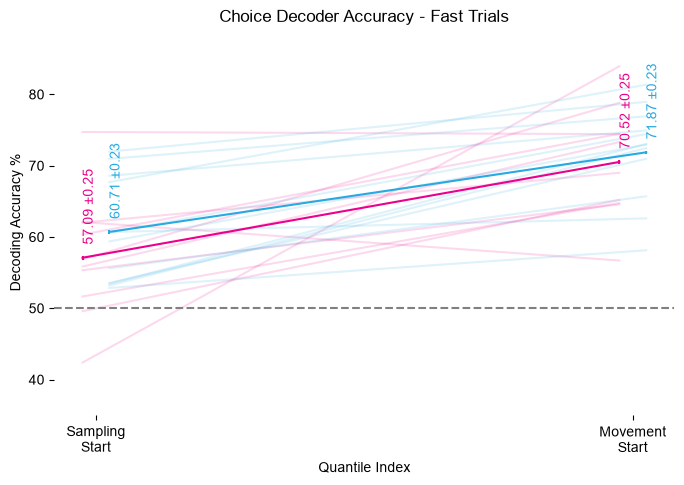

0      52.173913
1      65.217391
2      52.173913
3      69.565217
4      60.869565
         ...    
995    68.181818
996    77.272727
997    72.727273
998    77.272727
999    68.181818
Name: accuracy, Length: 44000, dtype: float64

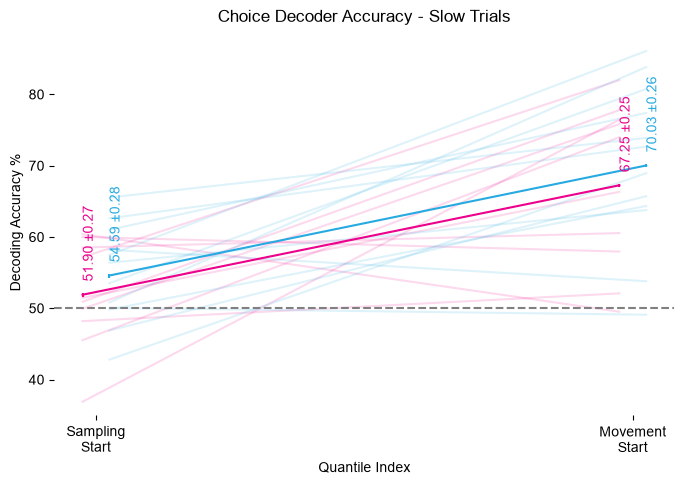

In [ ]:
from .twop.decoderplots import runAccuracyAcrossEpochs

runAccuracyAcrossEpochs(svm_df, save_figs=SAVE_FIGS,
                        fig_save_prefix=fig_save_prefix)

## Decoder accuracy across strategies

,BrainRegion,ShortName,accuracy,recall,precision,predictions_li,labels_li,epoch,DVstr,quantile_idx
0,6,GP4_23_s6_L50_D250_ALM,0.536232,0.536232,0.533281,"[0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
1,6,GP4_23_s6_L50_D250_ALM,0.608696,0.608696,0.609785,"[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...","[1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 1.0, ...",Sampling,NaN,NaN
2,6,GP4_23_s6_L50_D250_ALM,0.550725,0.550725,0.552145,"[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...",Sampling,NaN,NaN
3,6,GP4_23_s6_L50_D250_ALM,0.579710,0.579710,0.578700,"[0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...","[1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, ...",Sampling,NaN,NaN
4,6,GP4_23_s6_L50_D250_ALM,0.565217,0.565217,0.564269,"[0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...","[1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, ...",Sampling,NaN,NaN


0      52.173913
1      60.869565
2      65.217391
3      56.521739
4      39.130435
         ...    
995    63.636364
996    63.636364
997    72.727273
998    45.454545
999    72.727273
Name: accuracy, Length: 66000, dtype: float64

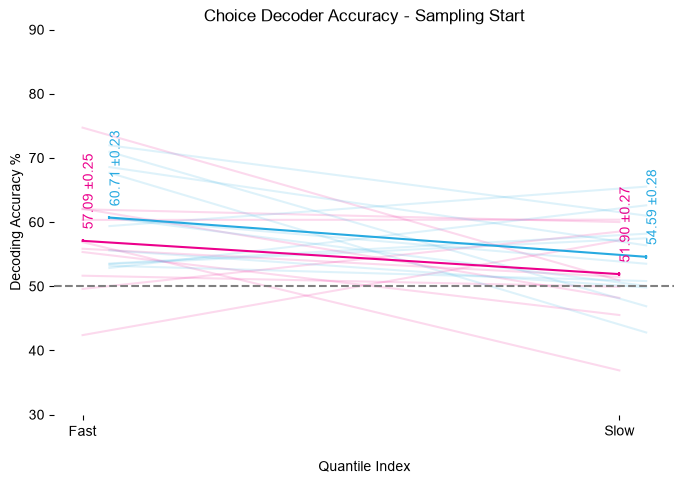

0      78.260870
1      69.565217
2      65.217391
3      60.869565
4      65.217391
         ...    
995    68.181818
996    77.272727
997    72.727273
998    77.272727
999    68.181818
Name: accuracy, Length: 66000, dtype: float64

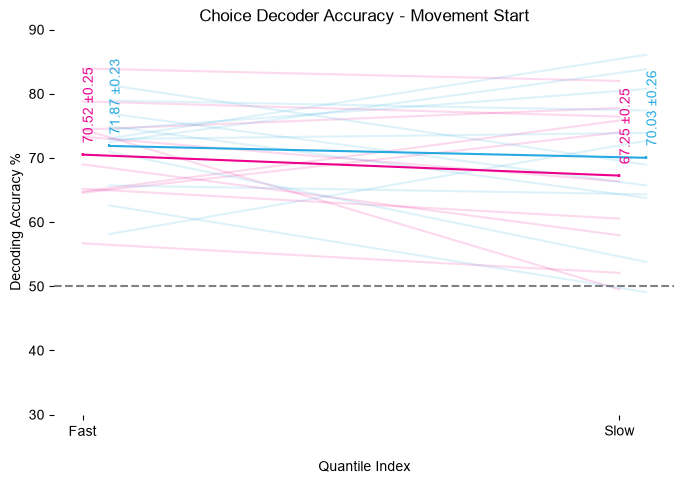

In [ ]:
# The same decoder accuracy, one figure per epoch with fast and slow side by
# side (twop/decoderplots.py).
from .twop.decoderplots import runAccuracyAcrossStrategies

runAccuracyAcrossStrategies(svm_df, save_figs=SAVE_FIGS,
                            fig_save_prefix=fig_save_prefix)